# Laboratorio 1 — Series de tiempo migratorias

Jorge Luis Lopez 221038

**Avance:** limpieza, análisis exploratorio general y análisis preliminar de las series.

La documentación advierte un quiebre metodológico desde 2023: `Viajero` deja de ser comparable y `Cruceristas` desaparece de esta fuente. Por ello, el análisis temporal principal usa **visitantes = Turista + Excursionista**, que sí es consistente en todo el período. Se eligen las categorías **Vía** y **Región dos**: tres series por cada categoría, además del total obligatorio.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from prophet import Prophet
import logging

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize': (12,5), 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

ARCHIVO = Path('Laboratorio 1. Series de Tiempo 2026 - Base_Migracion_2009-2026jun.xlsx')
df_raw = pd.read_excel(ARCHIVO, sheet_name='Datos')
print(f'Base original: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas')
display(df_raw.head())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


Base original: 161,036 filas × 13 columnas


,Año,Mes cod,Mes,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero
0,2009,1,Ene,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.00
1,2009,1,Ene,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.00
2,2009,1,Ene,Aérea,01 La Aurora,Angola,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA CENTRAL,08 OTROS,Resto del Mundo,Turista,4.00
3,2009,1,Ene,Aérea,01 La Aurora,Arabia Saudita,OTROS ORIENTE MEDIO,Oriente Medio,ORIENTE MEDIO,08 OTROS,Resto del Mundo,Turista,5.00
4,2009,1,Ene,Aérea,01 La Aurora,Argelia,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA DEL NORTE,08 OTROS,Resto del Mundo,Turista,1.00


## 1. Auditoría y limpieza

Se normalizan encabezados y espacios, se validan año, mes y cantidad, se eliminan duplicados exactos y se crea una fecha mensual. Los decimales son estimaciones expandidas válidas. Los ceros y valores altos se conservan: sin evidencia de error, quitarlos sesgaría los totales.

In [2]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=['object','string']).columns:
    df[col] = df[col].astype('string').str.strip().str.replace(r'\\s+', ' ', regex=True)
df['Región dos'] = df['Región dos'].replace('0', 'Sin clasificar')
df['Año'] = pd.to_numeric(df['Año'], errors='coerce').astype('Int64')
df['Mes cod'] = pd.to_numeric(df['Mes cod'], errors='coerce').astype('Int64')
df['Viajero'] = pd.to_numeric(df['Viajero'], errors='coerce')
duplicados = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
df['Fecha'] = pd.to_datetime(dict(year=df['Año'], month=df['Mes cod'], day=1), errors='coerce')
invalidas = df['Fecha'].isna() | df['Viajero'].isna() | df['Viajero'].lt(0)
n_invalidas = int(invalidas.sum())
df = df.loc[~invalidas].copy()

auditoria = pd.DataFrame({'Cantidad': {
    'Filas originales': len(df_raw), 'Duplicados exactos eliminados': duplicados,
    'Fecha/cantidad inválida eliminada': n_invalidas, 'Filas limpias': len(df),
    'Valores cero conservados': int(df.Viajero.eq(0).sum()),
    'Cantidades decimales conservadas': int(df.Viajero.mod(1).ne(0).sum()),
    'Meses observados': df.Fecha.nunique(), 'Cantidades negativas': int(df.Viajero.lt(0).sum())
}})
display(auditoria)
faltantes = df.drop(columns='Fecha').isna().sum().to_frame('Faltantes')
faltantes['Porcentaje'] = 100 * faltantes.Faltantes / len(df)
display(faltantes)
print(f'Cobertura: {df.Fecha.min():%Y-%m} a {df.Fecha.max():%Y-%m}')

# Diagnóstico de valores extremos a nivel de fila (no se eliminan automáticamente).
q1, q3 = df.Viajero.quantile([.25,.75]); iqr = q3-q1; limite = q3+1.5*iqr
marca_iqr = df.Viajero.gt(limite)
display(df.Viajero.describe(percentiles=[.01,.25,.5,.75,.95,.99]).to_frame().T)
print(f'Límite IQR: {limite:,.2f}; marcadas: {marca_iqr.sum():,} ({marca_iqr.mean():.1%})')
display(df.loc[marca_iqr].nlargest(10,'Viajero')[['Fecha','Vía','Frontera','País','Tipo de Viajero','Viajero']])

,Cantidad
Filas originales,161036
Duplicados exactos eliminados,0
Fecha/cantidad inválida eliminada,0
Filas limpias,161036
Valores cero conservados,54
Cantidades decimales conservadas,51272
Meses observados,210
Cantidades negativas,0


,Faltantes,Porcentaje
Año,0,0.00
Mes cod,0,0.00
Mes,0,0.00
Vía,0,0.00
Frontera,0,0.00
País,0,0.00
Región,0,0.00
Región dos,0,0.00
Regiones OMT,0,0.00
MCEO,0,0.00


Cobertura: 2009-01 a 2026-06


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
Viajero,"161,036.00",324.70,"2,387.75",0.00,0.40,2.00,7.00,38.89,858.26,"6,113.92","92,336.04"


Límite IQR: 94.23; marcadas: 26,390 (16.4%)


,Fecha,Vía,Frontera,País,Tipo de Viajero,Viajero
98206,2017-08-01,Terrestre,20 Melchor de Mencos,Belice,Viajero,"92,336.04"
124846,2019-12-01,Aérea,01 La Aurora,Guatemala,Turista,"83,511.00"
113144,2018-12-01,Aérea,01 La Aurora,Guatemala,Turista,"81,030.06"
143464,2022-12-01,Aérea,01 La Aurora,Guatemala,Turista,"76,588.00"
101056,2017-12-01,Aérea,01 La Aurora,Guatemala,Turista,"72,545.00"
158357,2025-12-01,Terrestre,07 Valle Nuevo,El Salvador,Turista,"69,806.00"
123854,2019-11-01,Aérea,01 La Aurora,Guatemala,Turista,"68,877.00"
153238,2024-12-01,Terrestre,07 Valle Nuevo,El Salvador,Turista,"68,085.77"
158279,2025-12-01,Aérea,01 La Aurora,Estados Unidos de América,Turista,"67,952.00"
77012,2015-12-01,Aérea,01 La Aurora,Guatemala,Turista,"67,786.00"


### Conclusión de la auditoría y los valores atípicos

La distribución de viajeros es asimétrica, algo esperado en datos agregados: las combinaciones correspondientes a mercados o fronteras grandes pueden registrar volúmenes muy superiores al resto. Las observaciones señaladas por el criterio IQR son plausibles y no existe evidencia de que sean errores, por lo que se conservaron para evitar sesgar los totales.

## 2. Análisis exploratorio general

El total bruto por tipo sirve para visualizar los quiebres. Todos los rankings y series posteriores usan únicamente turistas y excursionistas.

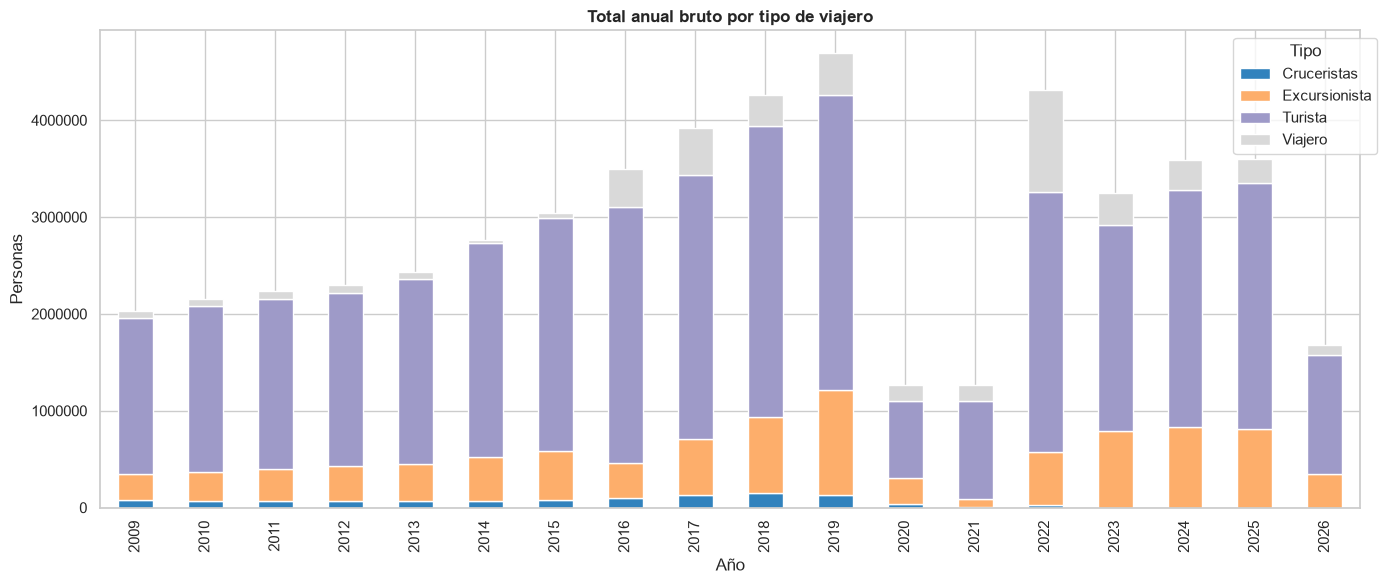

Tipo de Viajero,Cruceristas,Excursionista,Turista,Viajero
Año,,,,
2019,"130,789.00","1,081,250.85","3,050,999.75","428,780.60"
2020,"41,992.00","262,573.14","797,197.29","164,577.71"
2021,"3,908.00","82,470.05","1,016,494.33","164,895.39"
2022,"26,030.00","550,371.00","2,678,957.60","1,060,805.80"
2023,0.00,"793,847.06","2,123,979.75","330,882.19"
2024,0.00,"833,527.49","2,440,908.51","319,440.00"
2025,0.00,"811,391.52","2,540,897.14","244,949.34"
2026,0.00,"345,939.38","1,230,680.10","106,016.52"


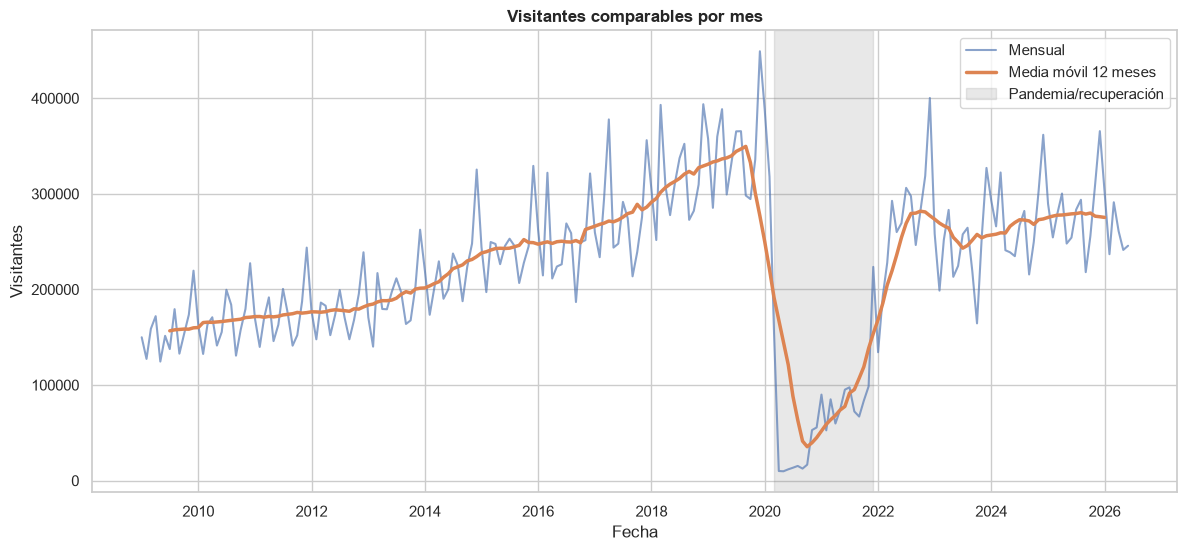

2019=4,132,251; 2020=1,059,770 (-74.4%); 2025=3,352,289 (-18.9%)


In [3]:
anual_tipo = df.groupby(['Año','Tipo de Viajero'])['Viajero'].sum().unstack(fill_value=0)
ax = anual_tipo.plot(kind='bar', stacked=True, figsize=(14,6), colormap='tab20c')
ax.set(title='Total anual bruto por tipo de viajero', xlabel='Año', ylabel='Personas')
ax.ticklabel_format(style='plain', axis='y')
plt.legend(title='Tipo', bbox_to_anchor=(1.02,1)); plt.tight_layout(); plt.show()
display(anual_tipo.tail(8))

visitantes = df[df['Tipo de Viajero'].isin(['Turista','Excursionista'])].copy()
mensual = visitantes.groupby('Fecha').Viajero.sum().sort_index().asfreq('MS', fill_value=0)
fig, ax = plt.subplots(figsize=(14,6))
ax.plot(mensual, alpha=.65, label='Mensual')
ax.plot(mensual.rolling(12,center=True).mean(), lw=2.5, label='Media móvil 12 meses')
ax.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2021-12-01'),color='gray',alpha=.18,label='Pandemia/recuperación')
ax.set(title='Visitantes comparables por mes', xlabel='Fecha', ylabel='Visitantes'); ax.legend(); plt.show()
v2019, v2020, v2025 = mensual['2019'].sum(), mensual['2020'].sum(), mensual['2025'].sum()
print(f'2019={v2019:,.0f}; 2020={v2020:,.0f} ({v2020/v2019-1:.1%}); 2025={v2025:,.0f} ({v2025/v2019-1:.1%})')

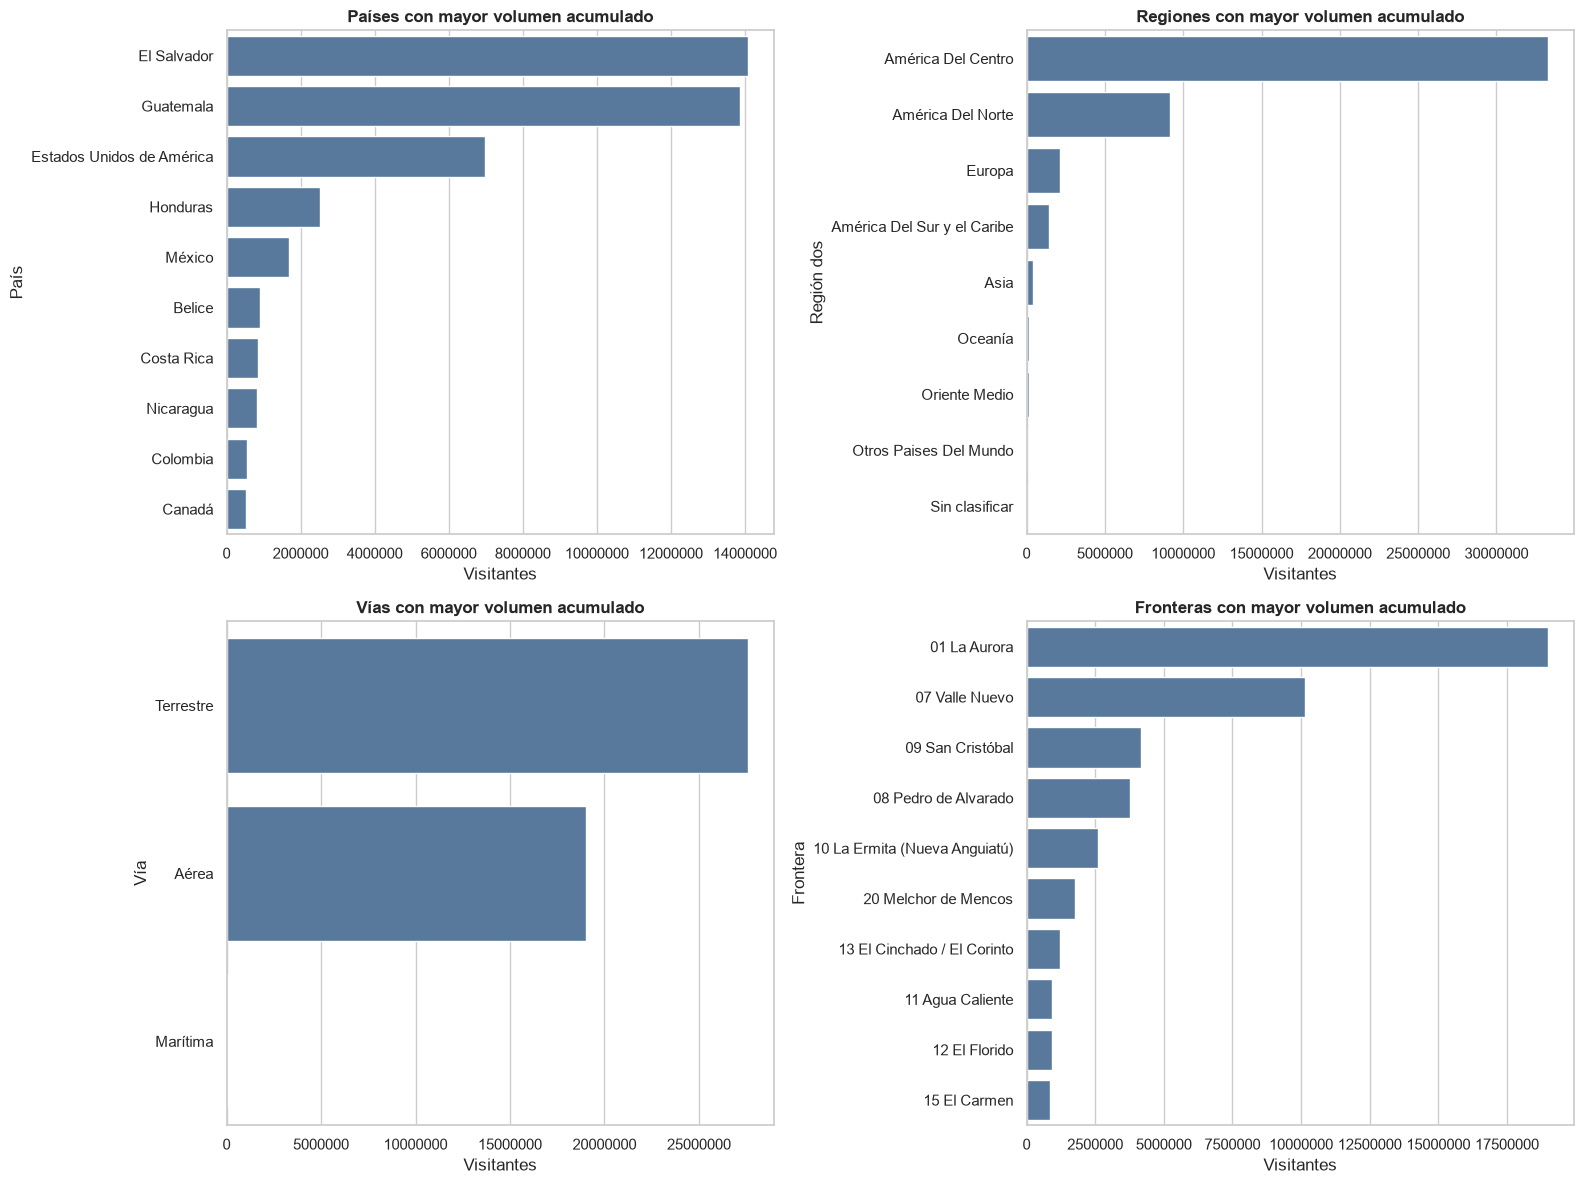


PAÍSES


,Visitantes
País,
El Salvador,"14,079,135.77"
Guatemala,"13,870,391.35"
Estados Unidos de América,"6,965,679.71"
Honduras,"2,520,974.31"
México,"1,678,422.55"
Belice,"916,101.07"
Costa Rica,"860,240.69"
Nicaragua,"811,145.39"
Colombia,"549,494.69"



REGIONES


,Visitantes
Región dos,
América Del Centro,"33,283,931.98"
América Del Norte,"9,160,810.15"
Europa,"2,149,271.06"
América Del Sur y el Caribe,"1,413,590.32"
Asia,"410,333.51"
Oceanía,"135,505.37"
Oriente Medio,"133,735.19"
Otros Paises Del Mundo,"23,914.30"
Sin clasificar,821.00



VÍAS


,Visitantes
Vía,
Terrestre,"27,592,253.33"
Aérea,"19,019,418.55"
Marítima,"100,241.00"



FRONTERAS


,Visitantes
Frontera,
01 La Aurora,"18,989,984.61"
07 Valle Nuevo,"10,143,045.32"
09 San Cristóbal,"4,183,631.71"
08 Pedro de Alvarado,"3,764,229.26"
10 La Ermita (Nueva Anguiatú),"2,587,072.27"
20 Melchor de Mencos,"1,782,864.39"
13 El Cinchado / El Corinto,"1,213,485.14"
11 Agua Caliente,"922,419.53"
12 El Florido,"910,373.47"


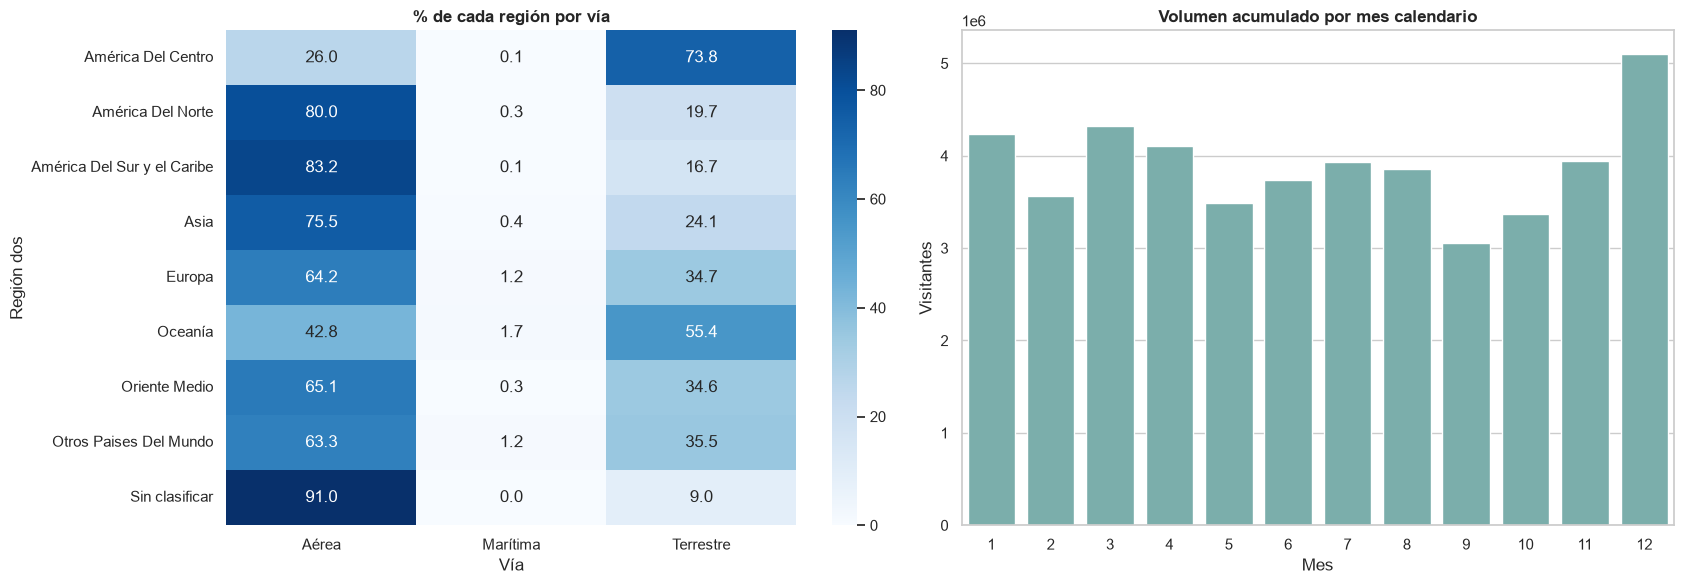

In [4]:
def ranking(col, n=10):
    return visitantes.groupby(col).Viajero.sum().sort_values(ascending=False).head(n).rename('Visitantes').to_frame()
rankings = {'Países':ranking('País'), 'Regiones':ranking('Región dos'),
            'Vías':ranking('Vía'), 'Fronteras':ranking('Frontera')}
fig, axes = plt.subplots(2,2,figsize=(16,12))
for ax,(titulo,tabla) in zip(axes.flat,rankings.items()):
    sns.barplot(data=tabla.reset_index(),x='Visitantes',y=tabla.index.name,ax=ax,color='#4C78A8')
    ax.set_title(f'{titulo} con mayor volumen acumulado'); ax.ticklabel_format(style='plain',axis='x')
plt.tight_layout(); plt.show()
for titulo,tabla in rankings.items():
    print(f'\n{titulo.upper()}')
    display(tabla)

cruce = pd.pivot_table(visitantes,index='Región dos',columns='Vía',values='Viajero',aggfunc='sum',fill_value=0)
fig, axes = plt.subplots(1,2,figsize=(17,6))
sns.heatmap(cruce.div(cruce.sum(axis=1),axis=0)*100,annot=True,fmt='.1f',cmap='Blues',ax=axes[0])
axes[0].set_title('% de cada región por vía')
patron_mes = visitantes.groupby('Mes cod').Viajero.sum().reindex(range(1,13))
sns.barplot(x=patron_mes.index,y=patron_mes.values,ax=axes[1],color='#72B7B2')
axes[1].set(title='Volumen acumulado por mes calendario',xlabel='Mes',ylabel='Visitantes')
plt.tight_layout(); plt.show()

### Conclusión del total anual por tipo de viajero

La gráfica muestra claramente el choque de la pandemia durante 2020. La reducción de la categoría `Viajero` en 2023 y la desaparición de `Cruceristas` no deben interpretarse como caídas equivalentes del turismo, pues coinciden con cambios en la fuente y en las definiciones del conjunto de datos.

### Conclusión de la evolución mensual

La serie mensual presenta crecimiento antes de 2020, un patrón estacional que se repite anualmente, una ruptura abrupta durante la pandemia y una recuperación posterior. El año 2026 contiene únicamente información de enero a junio, por lo que no es válido compararlo directamente con años completos.

### Conclusión de los rankings

El volumen acumulado se concentra principalmente en Centroamérica y en los ingresos por vía terrestre, mientras que el Aeropuerto Internacional La Aurora domina los ingresos aéreos. La columna `País` cambia de granularidad desde 2023; por ello, los mercados pequeños no son perfectamente comparables durante todo el período.

### Conclusión del cruce entre región, vía y mes

El cruce porcentual distingue regiones cuyos visitantes dependen principalmente de conexiones aéreas de aquellas dominadas por movimientos terrestres regionales. El patrón acumulado por mes muestra variaciones recurrentes dentro del año y respalda el uso de una frecuencia estacional de 12 meses.

## 3. Series mensuales y división 70/30

La división es cronológica para evitar fuga de información. Se construyen siete series: total, tres vías y las tres regiones principales según su acumulado de todo el período.

,Inicio,Fin,Frecuencia,Observaciones
Total visitantes,2009-01-01,2026-06-01,Mensual (12/año),210
Vía — Aérea,2009-01-01,2026-06-01,Mensual (12/año),210
Vía — Terrestre,2009-01-01,2026-06-01,Mensual (12/año),210
Vía — Marítima,2009-01-01,2026-06-01,Mensual (12/año),210
Región — América Del Centro,2009-01-01,2026-06-01,Mensual (12/año),210
Región — América Del Norte,2009-01-01,2026-06-01,Mensual (12/año),210
Región — Europa,2009-01-01,2026-06-01,Mensual (12/año),210


Entrenamiento: 147 (70.0%), 2009-01–2021-03
Prueba: 63 (30.0%), 2021-04–2026-06


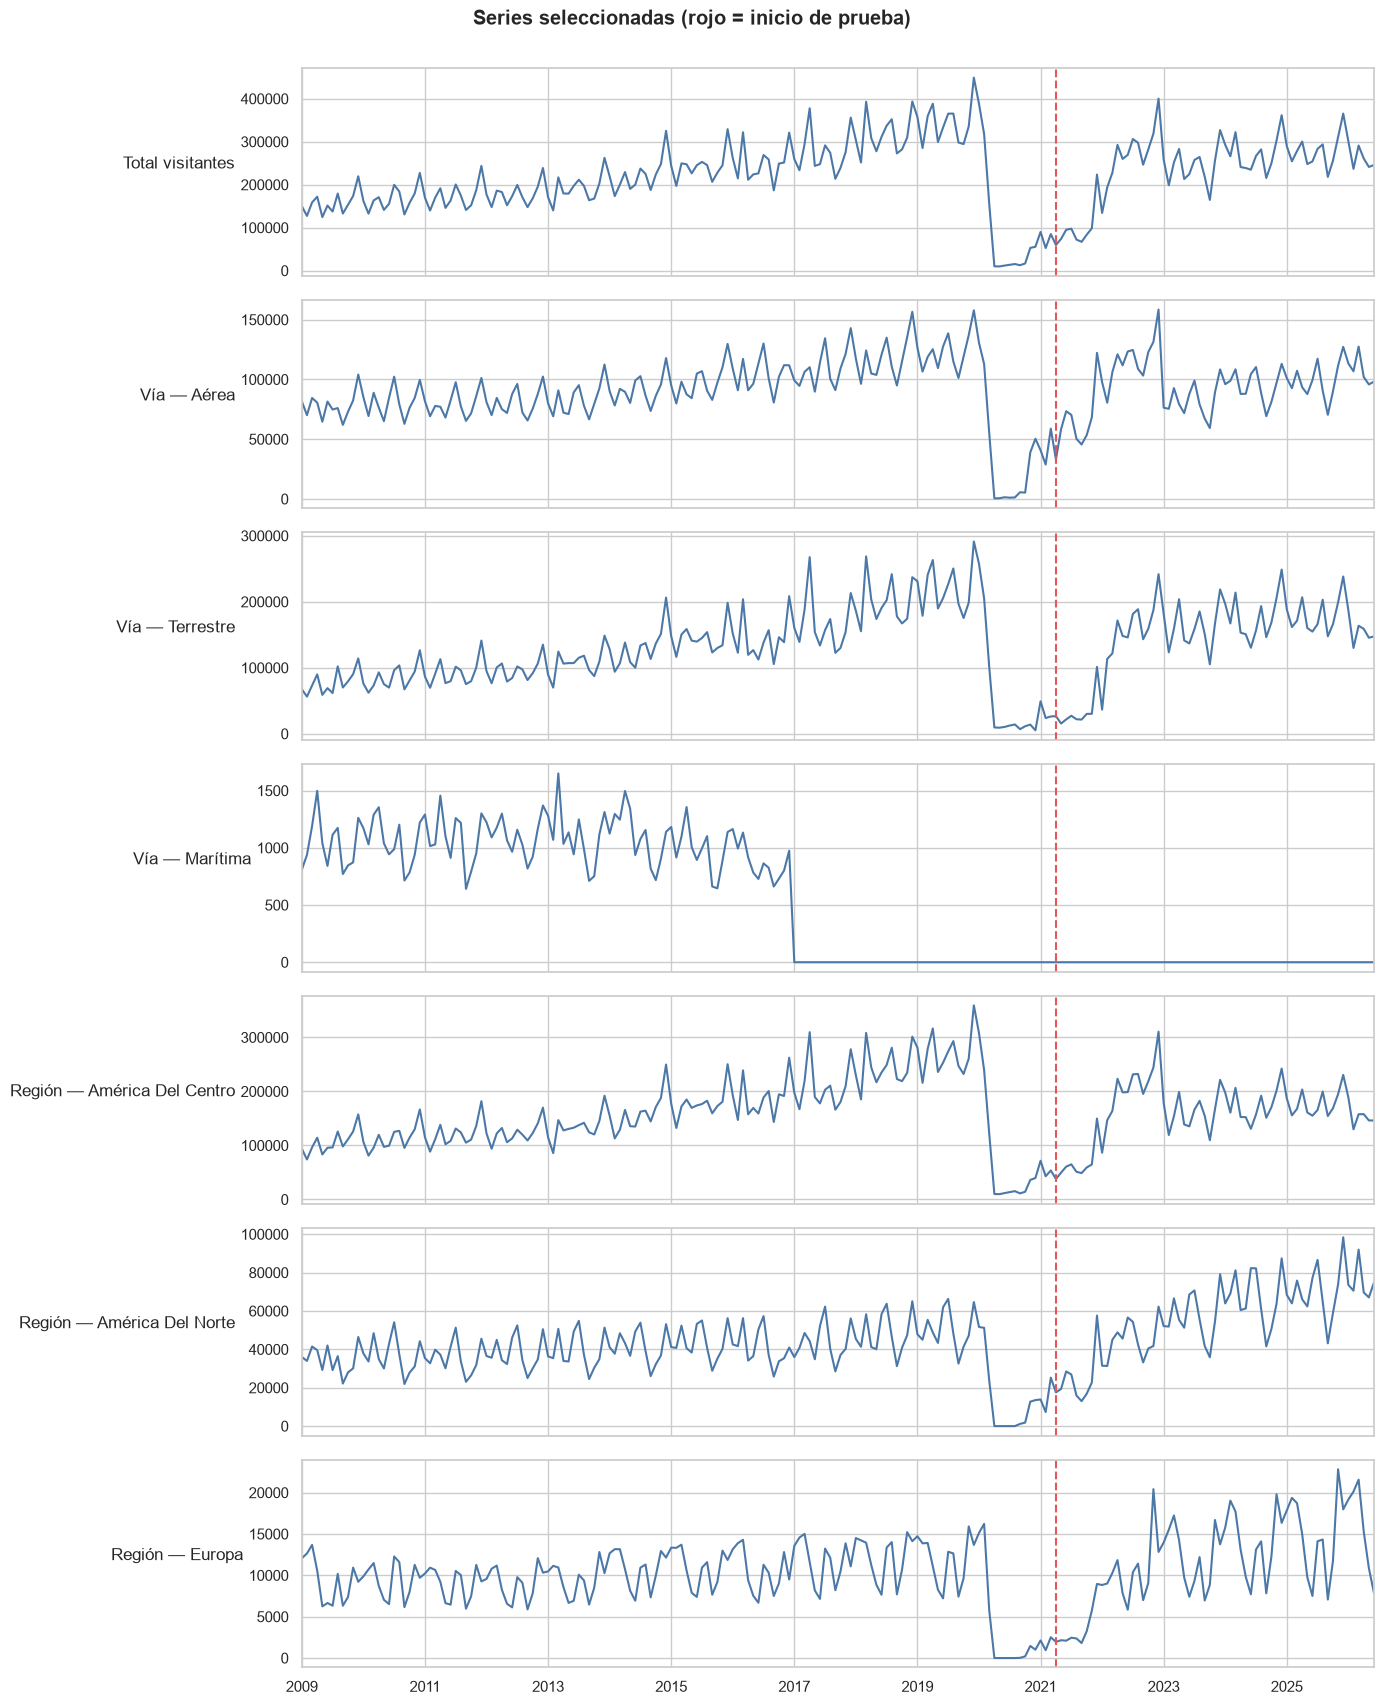

In [5]:
indice = pd.date_range(visitantes.Fecha.min(), visitantes.Fecha.max(), freq='MS')
def crear_serie(mascara=None):
    x = visitantes if mascara is None else visitantes.loc[mascara]
    return x.groupby('Fecha').Viajero.sum().reindex(indice,fill_value=0).astype(float)

series = {'Total visitantes':crear_serie()}
for via in ['Aérea','Terrestre','Marítima']:
    series[f'Vía — {via}'] = crear_serie(visitantes.Vía.eq(via))
top_regiones = visitantes.groupby('Región dos').Viajero.sum().nlargest(3).index
for region in top_regiones:
    series[f'Región — {region}'] = crear_serie(visitantes['Región dos'].eq(region))
series_df = pd.DataFrame(series,index=indice)
corte = int(np.floor(.70*len(series_df)))
train,test = series_df.iloc[:corte],series_df.iloc[corte:]
meta = pd.DataFrame({'Inicio':series_df.apply(lambda s:s.first_valid_index()),
                     'Fin':series_df.apply(lambda s:s.last_valid_index()),
                     'Frecuencia':'Mensual (12/año)','Observaciones':series_df.notna().sum()})
display(meta)
print(f'Entrenamiento: {len(train)} ({len(train)/len(series_df):.1%}), {train.index.min():%Y-%m}–{train.index.max():%Y-%m}')
print(f'Prueba: {len(test)} ({len(test)/len(series_df):.1%}), {test.index.min():%Y-%m}–{test.index.max():%Y-%m}')
axes=series_df.plot(subplots=True,figsize=(14,17),sharex=True,legend=False,color='#4C78A8')
for ax,nombre in zip(axes,series_df.columns):
    ax.set_ylabel(nombre,rotation=0,ha='right'); ax.axvline(test.index.min(),color='#E45756',ls='--')
plt.suptitle('Series seleccionadas (rojo = inicio de prueba)',y=1.002,fontweight='bold'); plt.tight_layout(); plt.show()

## 4. Análisis preliminar de las siete series

ADF contrasta la hipótesis nula de raíz unitaria/no estacionariedad (`p < 0.05` permite rechazarla). La ACF en niveles, la descomposición y la estabilidad de varianza complementan la prueba. El choque pandémico es una ruptura estructural, por lo que ninguna prueba aislada debe interpretarse mecánicamente.

,p ADF nivel,p ADF diferencia 1,p ADF diferencia 12,CV pre-COVID mitad 1,CV pre-COVID mitad 2,Razón varianzas,Cambio 2020 vs 2019,Transformación sugerida,d preliminar
Total visitantes,0.0470,0.0018,0.0199,0.171,0.205,3.68,-74.4%,log1p,0
Vía — Aérea,0.0207,0.0004,0.0179,0.141,0.167,2.53,-72.8%,log1p,0
Vía — Terrestre,0.0298,0.0082,0.0373,0.225,0.256,4.41,-75.2%,log1p,0
Vía — Marítima,0.6797,0.0061,0.0824,0.196,1.141,5.23,nan%,log1p,1
Región — América Del Centro,0.0449,0.0010,0.0190,0.198,0.233,4.34,-74.4%,log1p,0
Región — América Del Norte,0.2197,0.0067,0.0482,0.221,0.226,1.49,-74.1%,No imprescindible,1
Región — Europa,0.0216,0.0274,0.0427,0.234,0.230,1.41,-71.8%,No imprescindible,0


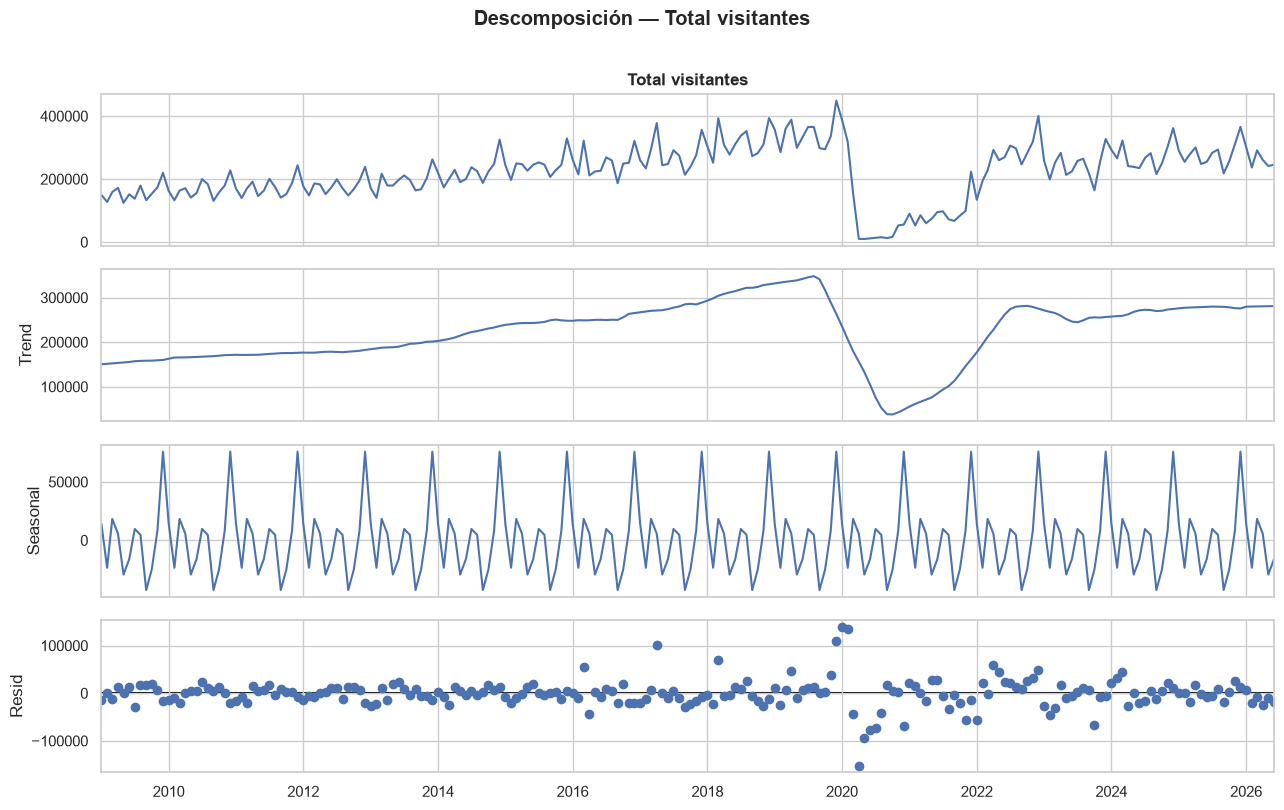

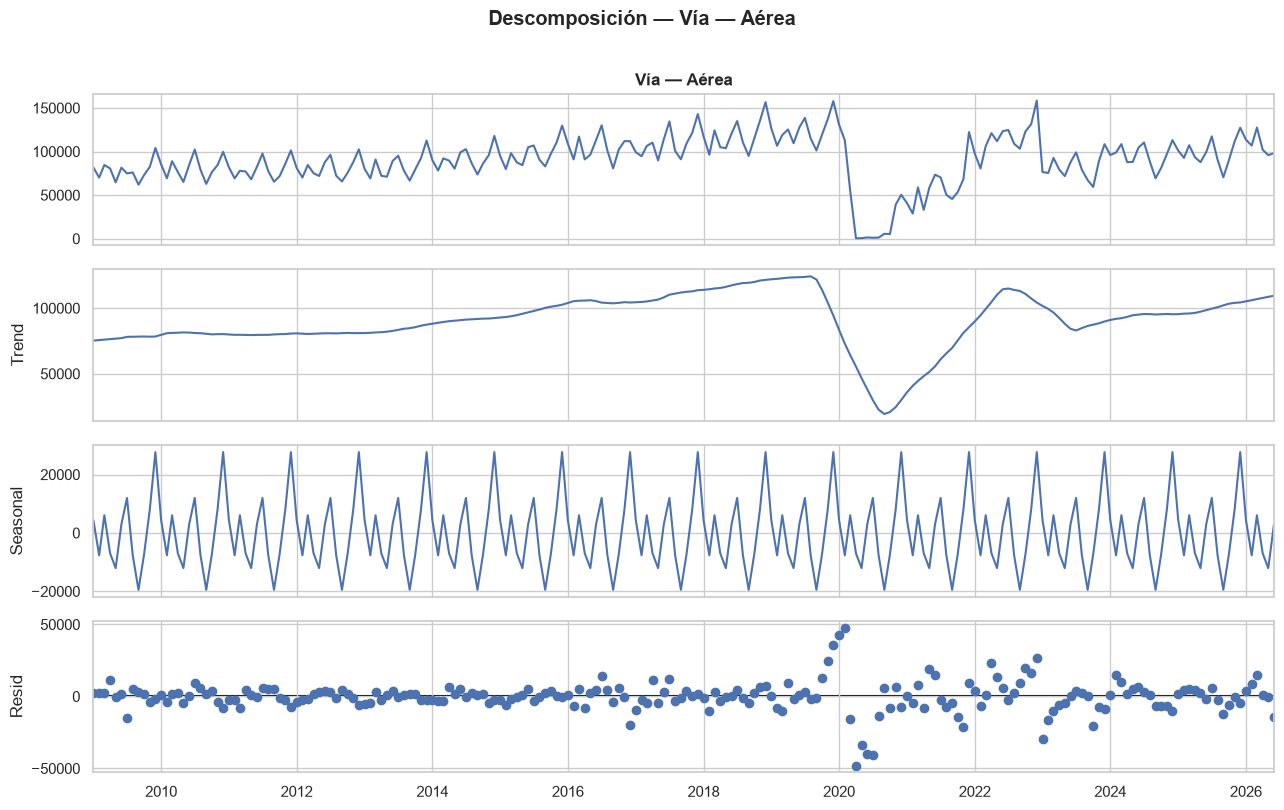

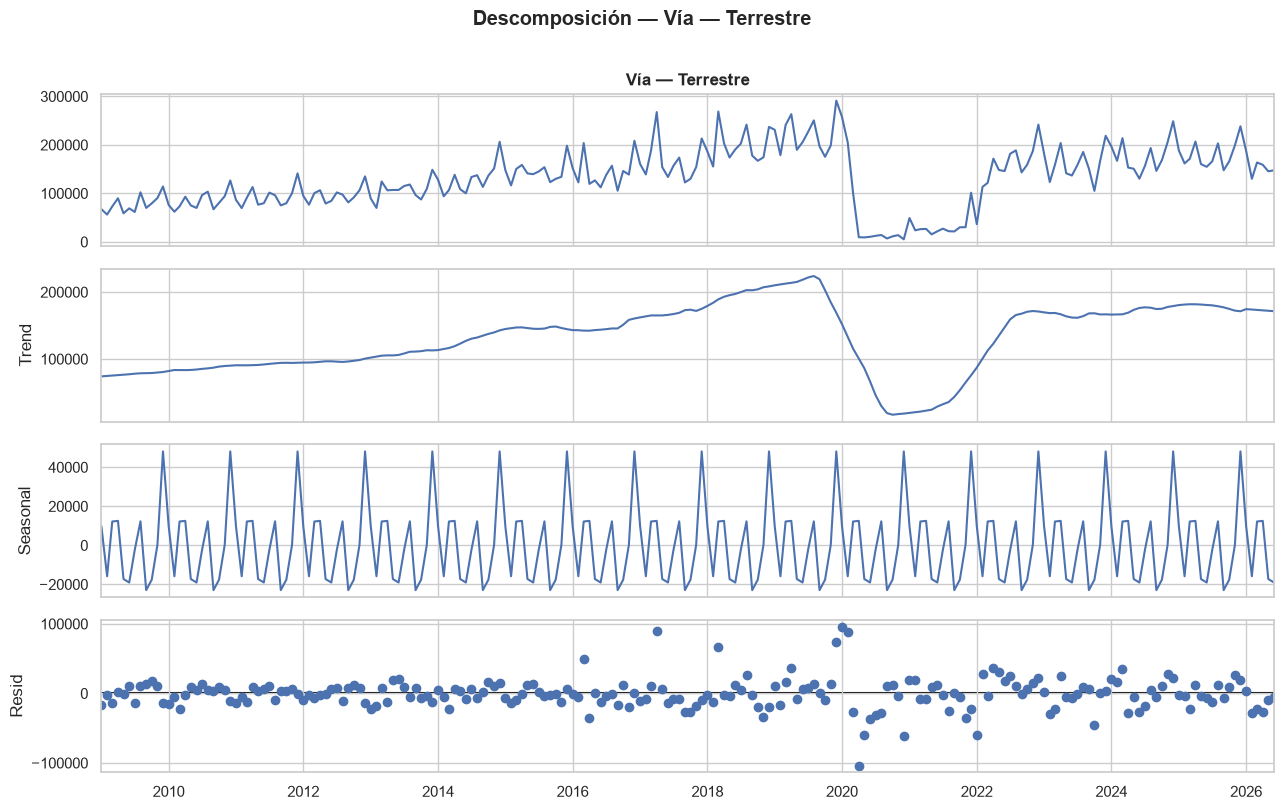

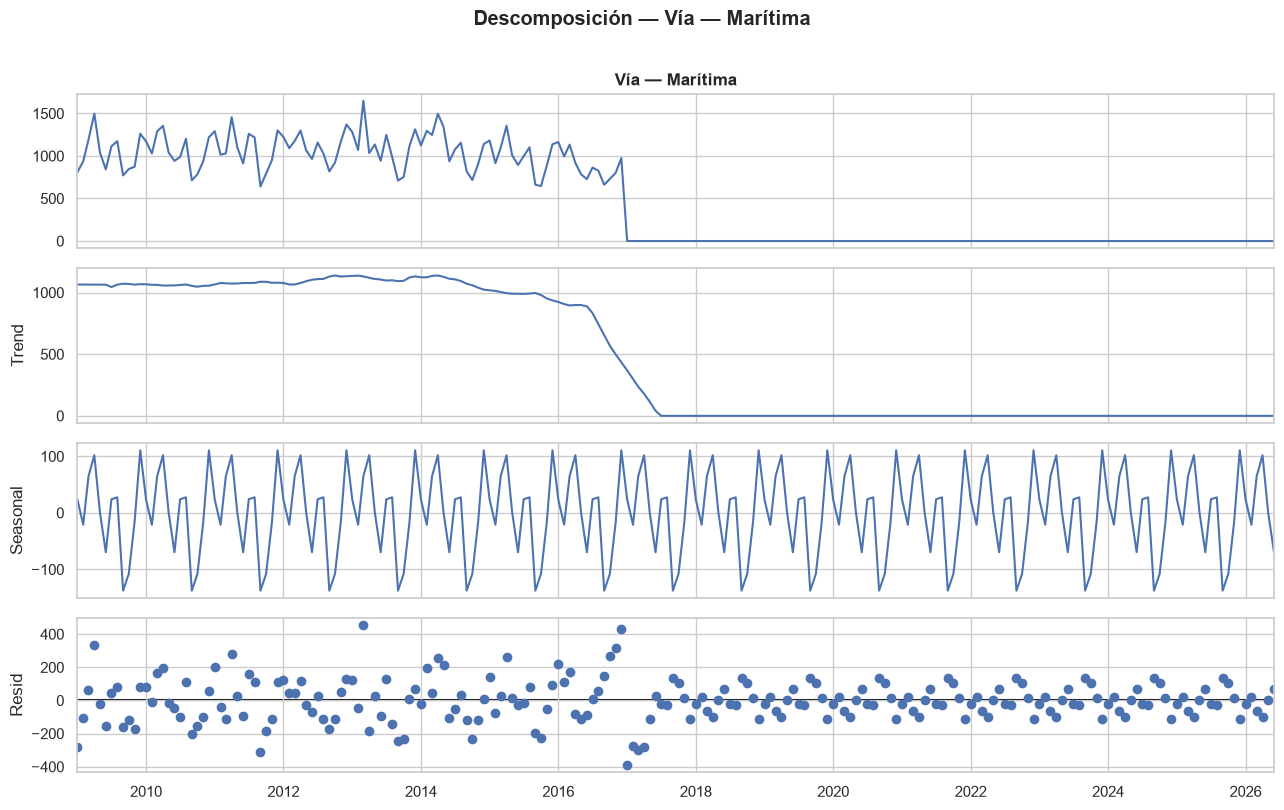

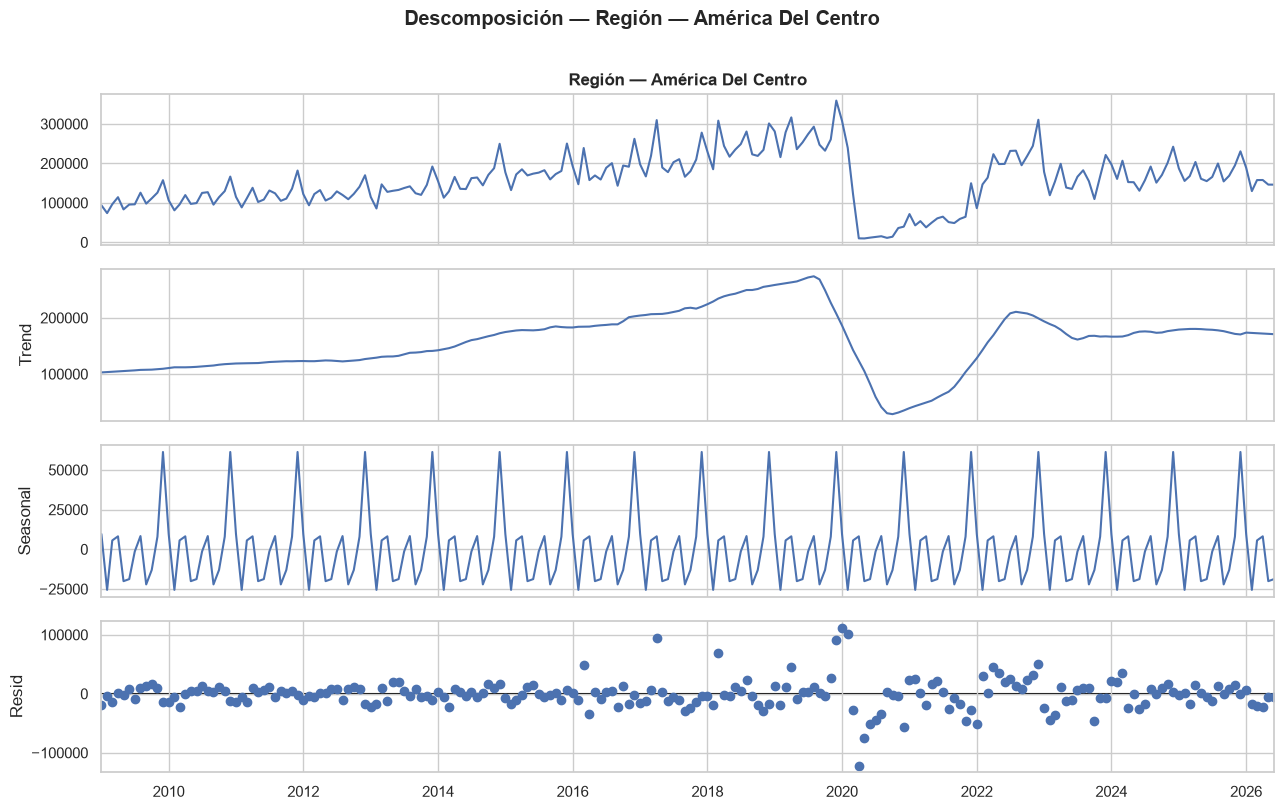

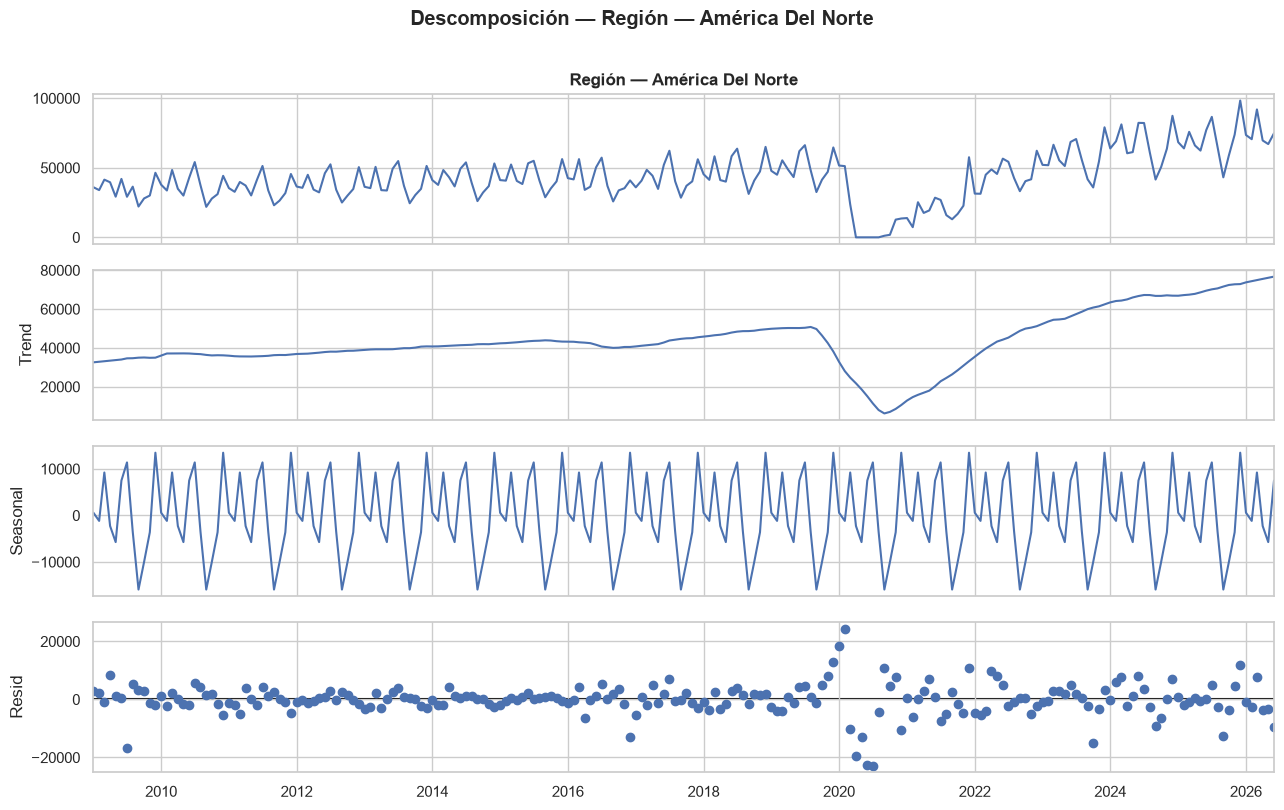

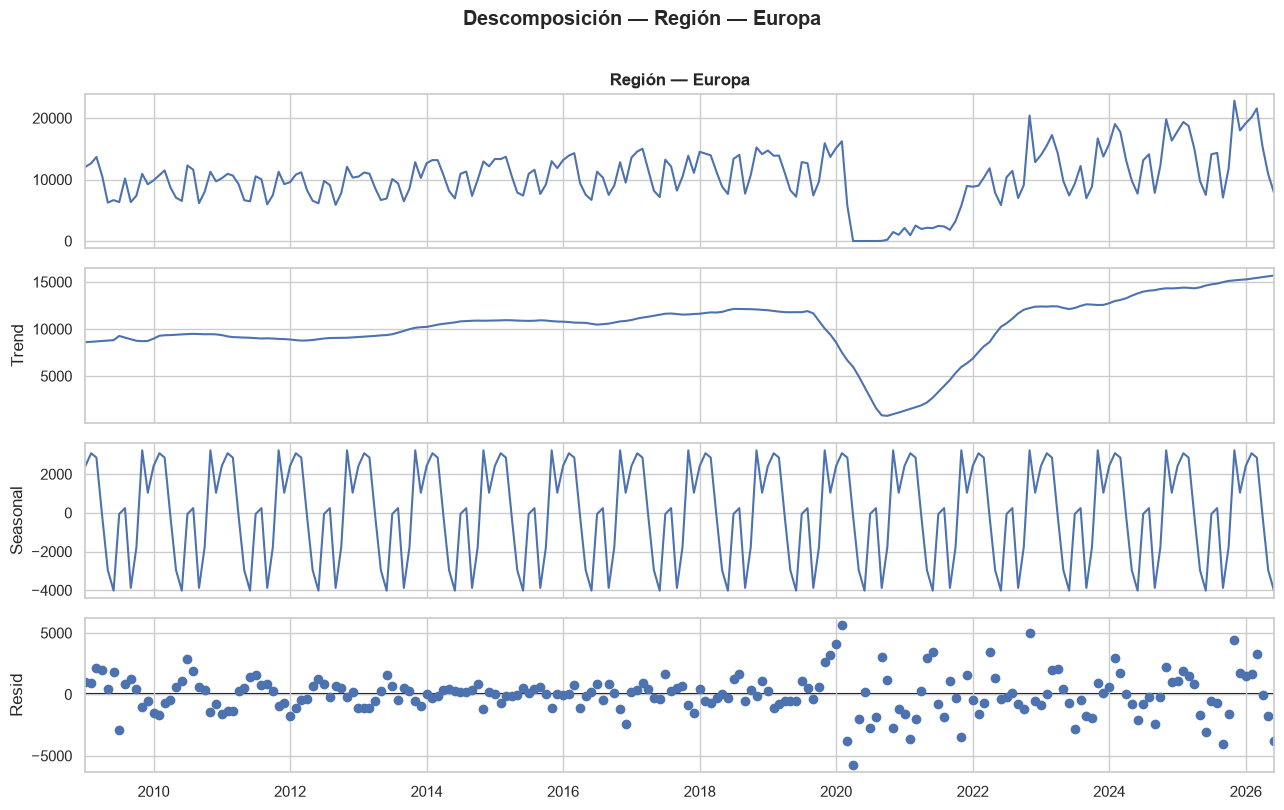

In [6]:
def adf_p(s):
    s=pd.Series(s).dropna()
    return adfuller(s,autolag='AIC')[1] if len(s)>=20 and s.nunique()>1 else np.nan

def diagnostico(nombre,s):
    pre=s.loc[:'2019-12-01']; m=len(pre)//2; a,b=pre.iloc[:m],pre.iloc[m:]
    cv1,cv2=a.std()/a.mean(),b.std()/b.mean(); rv=b.var()/a.var()
    impacto=s.loc['2020'].sum()/s.loc['2019'].sum()-1
    p0,p1,p12=adf_p(s),adf_p(s.diff()),adf_p(s.diff(12))
    return {'p ADF nivel':p0,'p ADF diferencia 1':p1,'p ADF diferencia 12':p12,
            'CV pre-COVID mitad 1':cv1,'CV pre-COVID mitad 2':cv2,'Razón varianzas':rv,
            'Cambio 2020 vs 2019':impacto,
            'Transformación sugerida':'log1p' if rv>2 or cv2>1.35*cv1 else 'No imprescindible',
            'd preliminar':0 if p0<.05 else 1}
diag=pd.DataFrame({n:diagnostico(n,s) for n,s in series_df.items()}).T
display(diag.style.format({'p ADF nivel':'{:.4f}','p ADF diferencia 1':'{:.4f}',
 'p ADF diferencia 12':'{:.4f}','CV pre-COVID mitad 1':'{:.3f}','CV pre-COVID mitad 2':'{:.3f}',
 'Razón varianzas':'{:.2f}','Cambio 2020 vs 2019':'{:.1%}'}))

for nombre,s in series_df.items():
    dec=seasonal_decompose(s,model='additive',period=12,extrapolate_trend='freq')
    fig=dec.plot(); fig.set_size_inches(13,8); fig.suptitle(f'Descomposición — {nombre}',y=1.01,fontweight='bold')
    plt.tight_layout(); plt.show()

<br>

### Conclusión de las descomposiciones

Las descomposiciones muestran que la tendencia y el patrón estacional no permanecen constantes durante todo el período. Los residuos excepcionalmente grandes alrededor de 2020 reflejan una intervención externa que la tendencia y la estacionalidad ordinarias no pueden explicar. Se utilizó una descomposición aditiva porque algunas series presentan valores cercanos a cero durante la pandemia, lo cual vuelve inadecuada una descomposición multiplicativa.

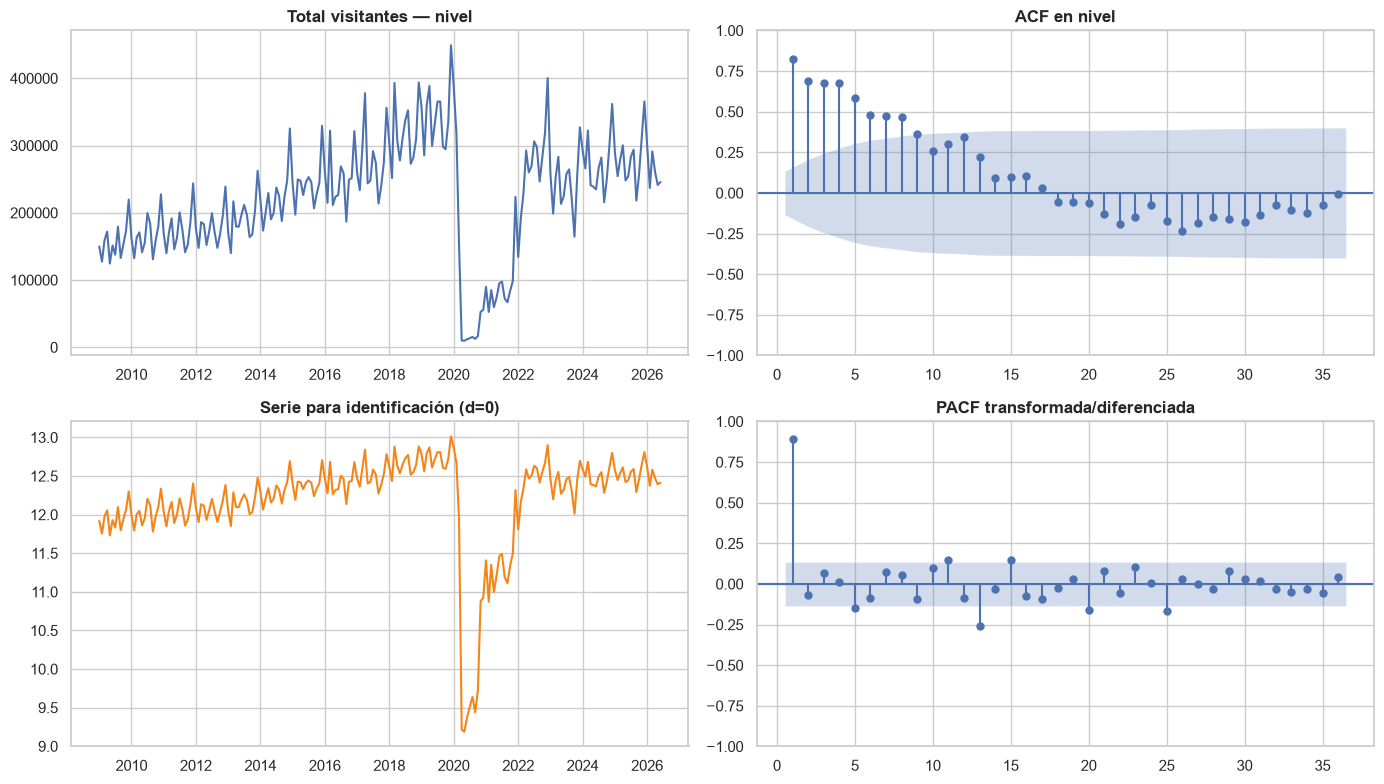

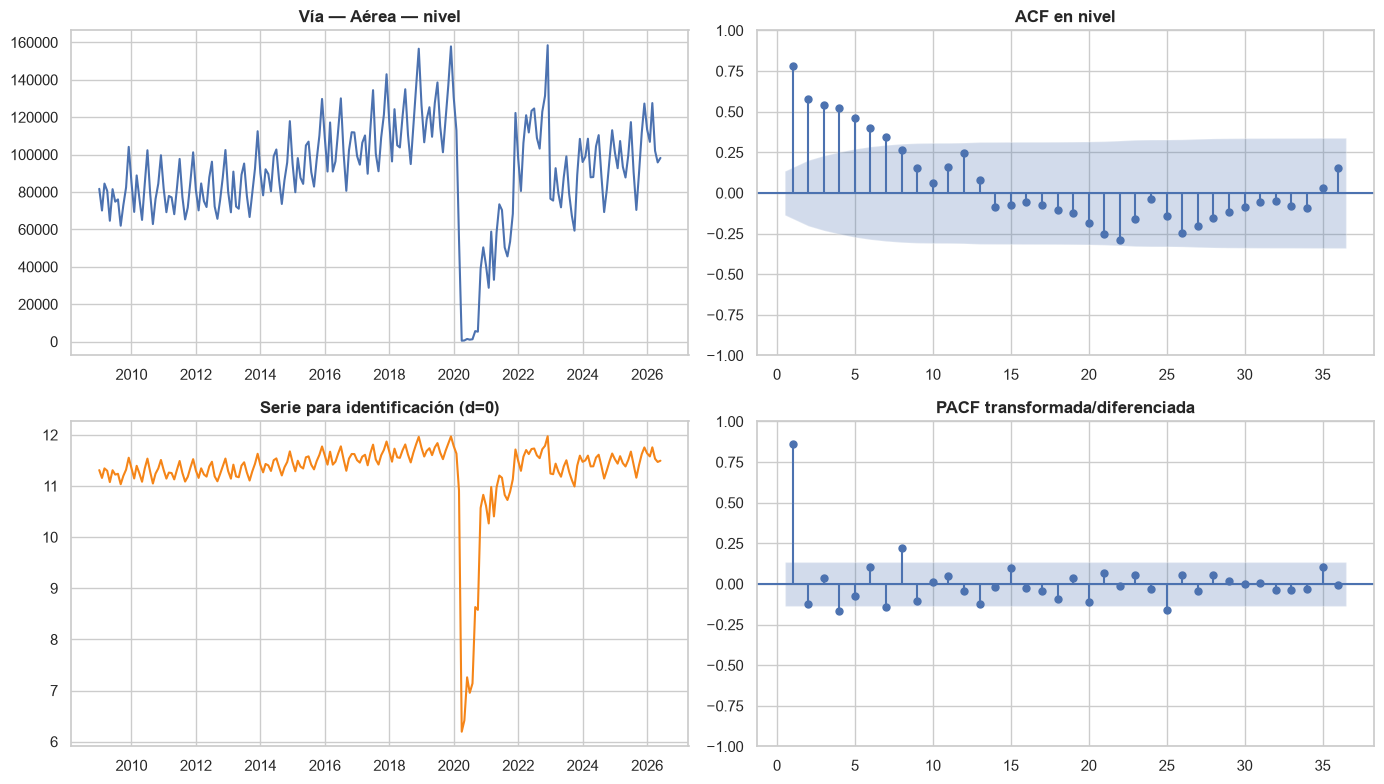

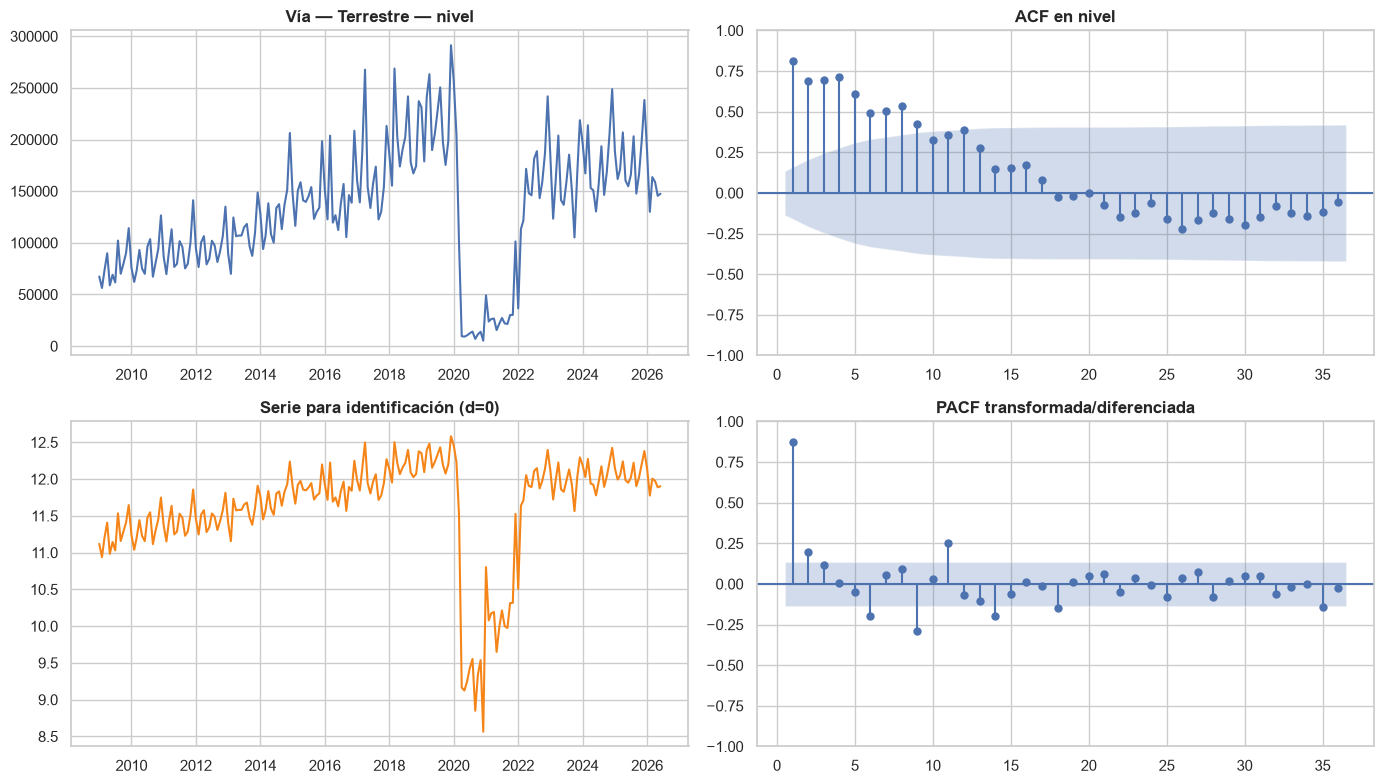

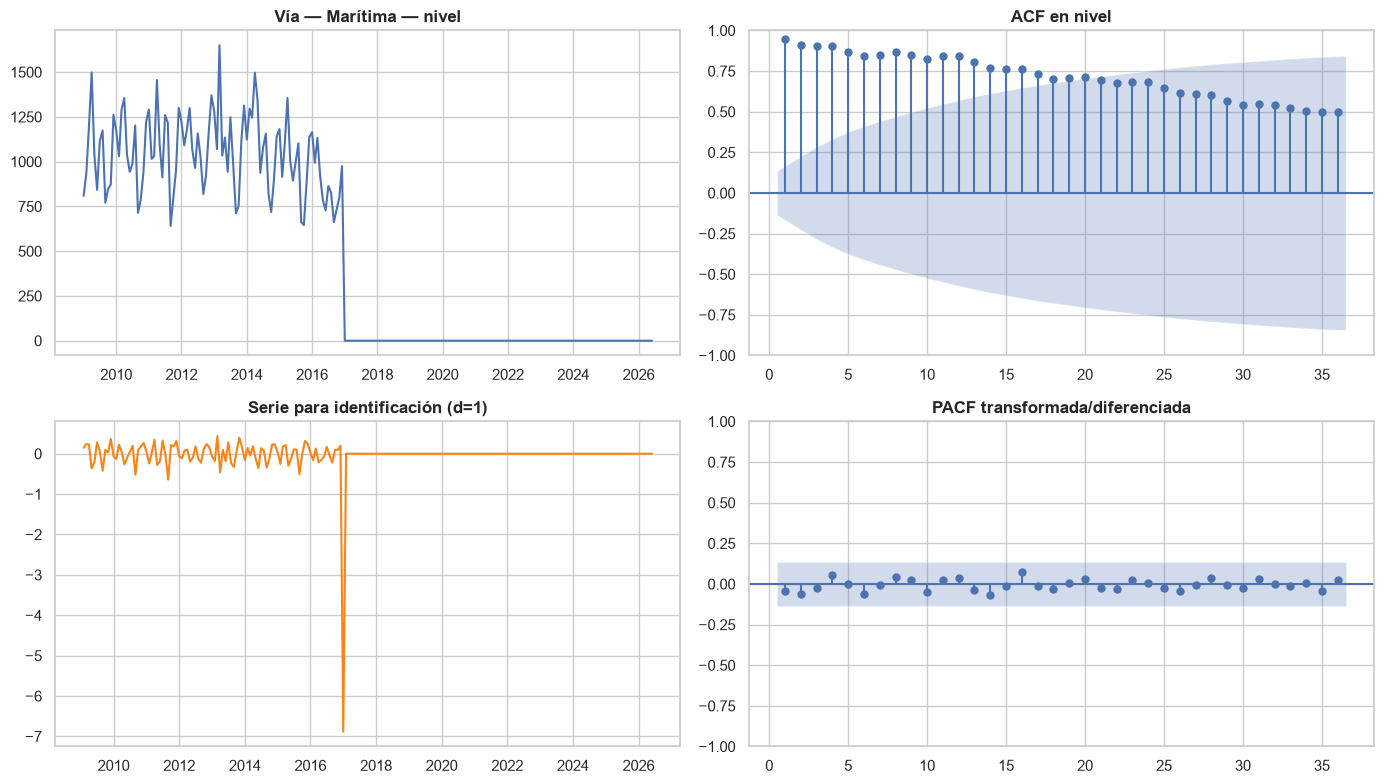

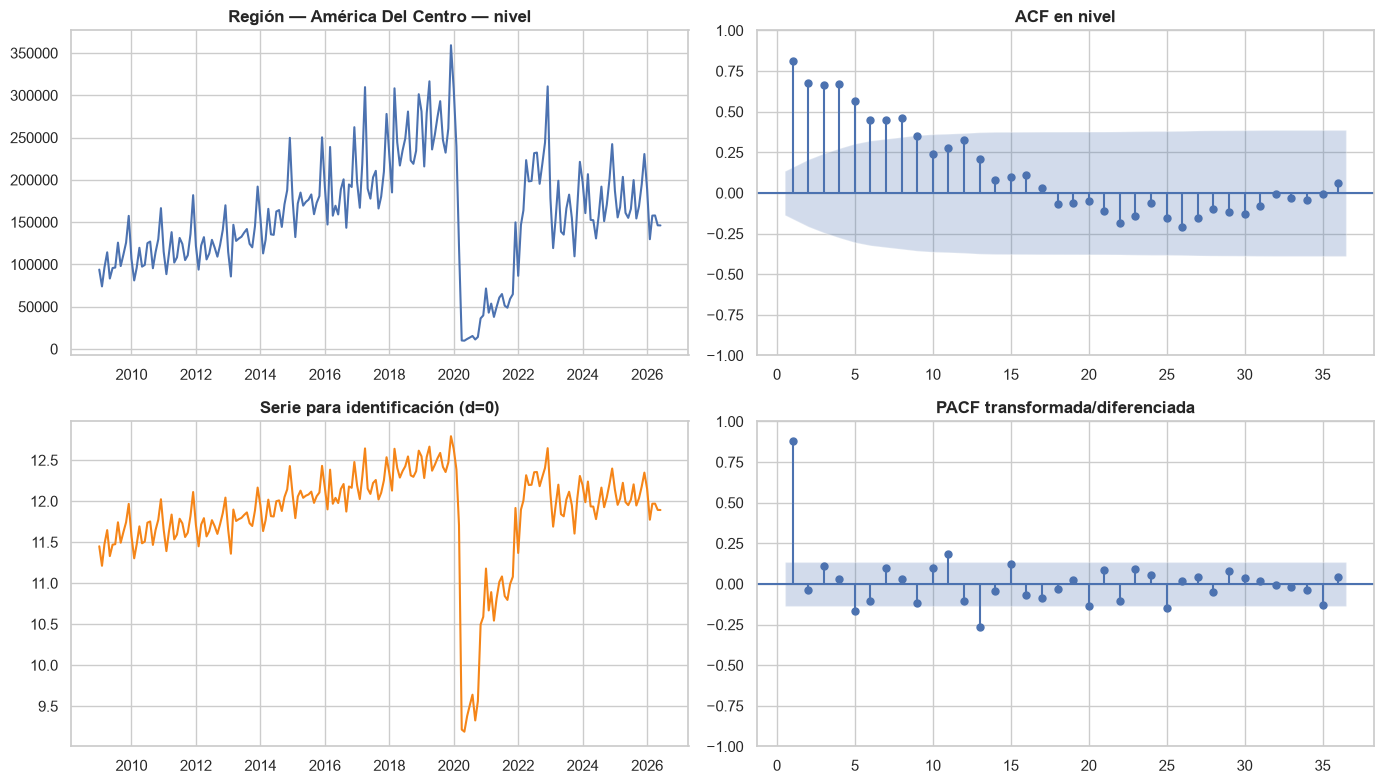

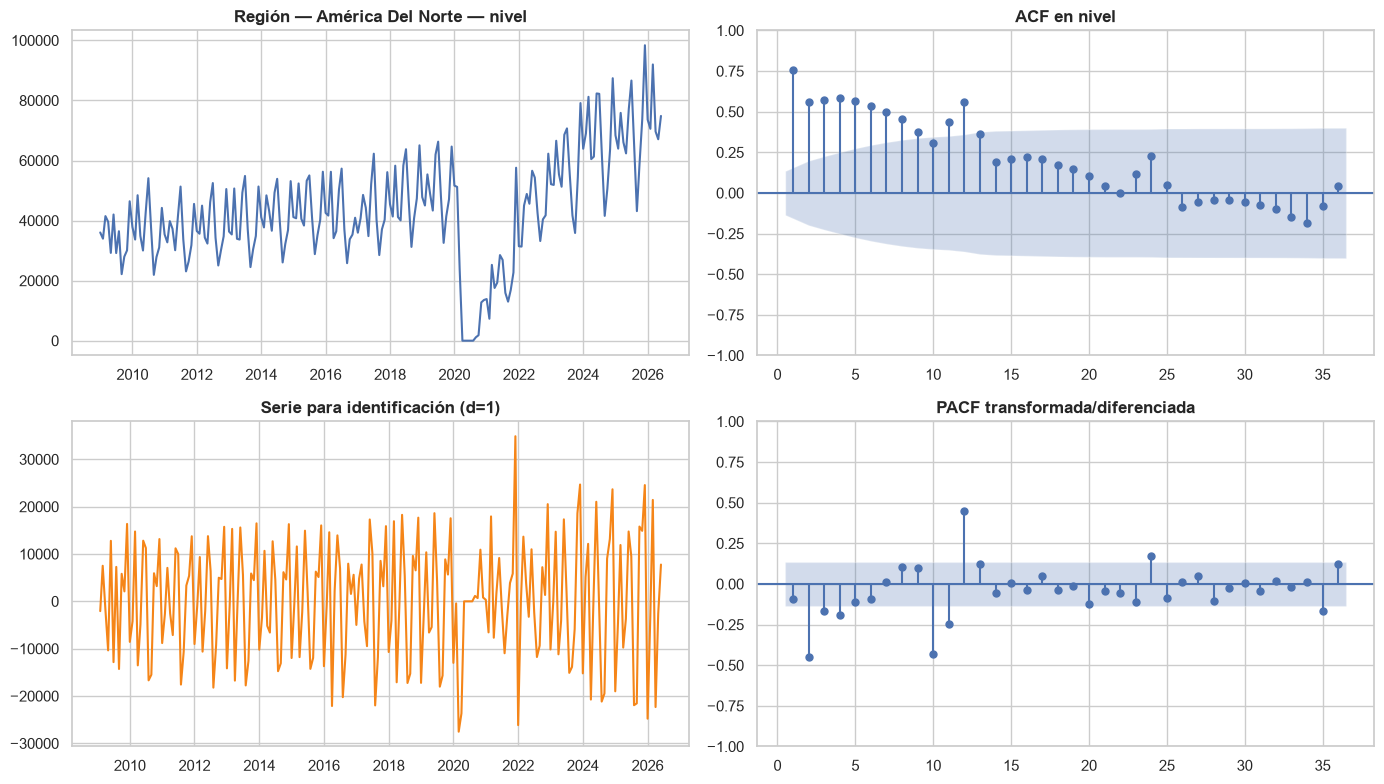

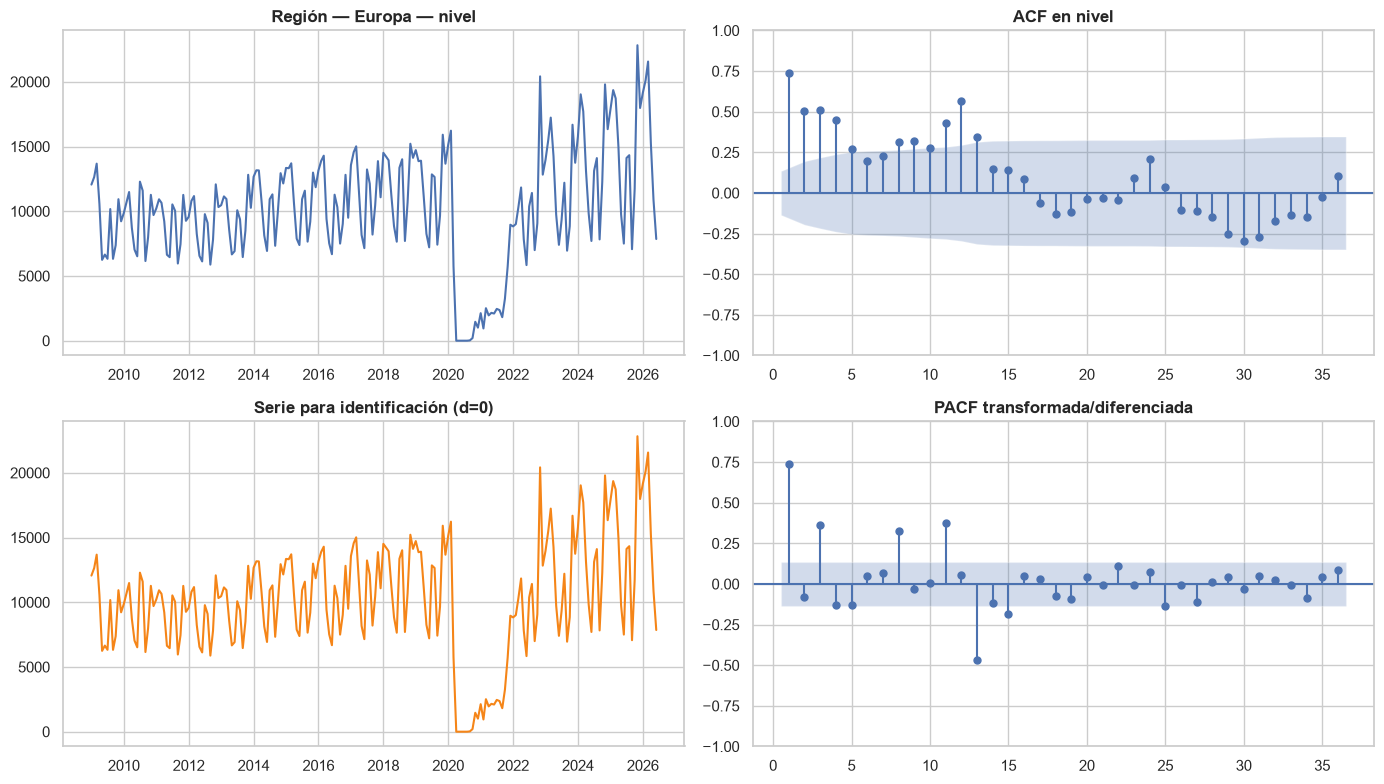

In [7]:
for nombre,s in series_df.items():
    d=int(diag.loc[nombre,'d preliminar'])
    base=np.log1p(s) if diag.loc[nombre,'Transformación sugerida']=='log1p' else s
    est=base.diff().dropna() if d else base.dropna()
    fig,axes=plt.subplots(2,2,figsize=(14,8))
    axes[0,0].plot(s); axes[0,0].set_title(f'{nombre} — nivel')
    plot_acf(s,lags=36,zero=False,ax=axes[0,1]); axes[0,1].set_title('ACF en nivel')
    axes[1,0].plot(est,color='#F58518'); axes[1,0].set_title(f'Serie para identificación (d={d})')
    plot_pacf(est,lags=min(36,len(est)//2-1),zero=False,method='ywm',ax=axes[1,1]); axes[1,1].set_title('PACF transformada/diferenciada')
    plt.tight_layout(); plt.show()

<br>

### Conclusión de las gráficas ACF y PACF

En las series donde la ACF en niveles disminuye lentamente existe evidencia visual de no estacionariedad en media. Después de aplicar la transformación o diferenciación indicada, los primeros rezagos significativos de la PACF ayudan a proponer el parámetro autorregresivo `p`, mientras que los de la ACF orientan el parámetro de medias móviles `q`. Los picos alrededor de los rezagos 12, 24 y 36 indican dependencia estacional anual. Estos resultados generan modelos candidatos, pero la selección definitiva deberá basarse también en sus residuos y métricas de desempeño.

In [8]:
comparativo=[]
for nombre,s in series_df.items():
    dec=seasonal_decompose(s,model='additive',period=12,extrapolate_trend='freq')
    fuerza=max(0,1-np.var(dec.resid)/np.var(dec.resid+dec.seasonal))
    pre=s.loc[:'2019-12-01']; pendiente=np.polyfit(np.arange(len(pre)),pre,1)[0]
    volatilidad=pre.pct_change().replace([np.inf,-np.inf],np.nan).dropna().std()
    comparativo.append([nombre,fuerza,pendiente,volatilidad,diag.loc[nombre,'Cambio 2020 vs 2019']])
comparativo=pd.DataFrame(comparativo,columns=['Serie','Fuerza estacional','Tendencia pre-COVID (personas/mes)','Volatilidad pre-COVID','Impacto 2020 vs 2019']).set_index('Serie')
display(comparativo.style.format({'Fuerza estacional':'{:.3f}','Tendencia pre-COVID (personas/mes)':'{:,.1f}','Volatilidad pre-COVID':'{:.3f}','Impacto 2020 vs 2019':'{:.1%}'}))
print('Mayor estacionalidad:',comparativo['Fuerza estacional'].idxmax())
print('Mayor crecimiento absoluto:',comparativo['Tendencia pre-COVID (personas/mes)'].idxmax())
print('Mayor volatilidad relativa:',comparativo['Volatilidad pre-COVID'].idxmax())
print('Más afectada por pandemia:',comparativo['Impacto 2020 vs 2019'].idxmin())

,Fuerza estacional,Tendencia pre-COVID (personas/mes),Volatilidad pre-COVID,Impacto 2020 vs 2019
Serie,,,,
Total visitantes,0.495,"1,558.4",0.202,-74.4%
Vía — Aérea,0.562,407.3,0.171,-72.8%
Vía — Terrestre,0.432,"1,161.1",0.256,-75.2%
Vía — Marítima,0.253,-10.0,0.246,nan%
Región — América Del Centro,0.451,"1,369.1",0.224,-74.4%
Región — América Del Norte,0.703,116.6,0.271,-74.1%
Región — Europa,0.727,25.1,0.301,-71.8%


Mayor estacionalidad: Región — Europa
Mayor crecimiento absoluto: Total visitantes
Mayor volatilidad relativa: Región — Europa
Más afectada por pandemia: Vía — Terrestre


<br>

### Conclusión de la comparación preliminar

La tabla comparativa cuantifica las diferencias observadas gráficamente entre las series. Europa presenta la mayor fuerza estacional y la mayor volatilidad relativa antes de la pandemia; el total de visitantes registra el mayor crecimiento absoluto previo a 2020; y la vía terrestre experimenta la mayor contracción porcentual entre 2019 y 2020.

## Cierre de la etapa exploratoria

- La base tiene cobertura mensual completa, sin faltantes, duplicados exactos ni cantidades negativas. Los extremos plausibles se conservaron.
- Para comparar 2009–2026 se usa `Turista + Excursionista`; sumar todas las categorías crearía quiebres artificiales.
- Las siete series exhiben combinaciones de tendencia, estacionalidad y una ruptura pandémica. Las tablas ADF y gráficas ACF/PACF indican la transformación y diferenciación preliminares.
- El corte 70/30 es cronológico. Como cae cerca de la pandemia, la prueba será exigente y el cambio estructural deberá explicarse al evaluar pronósticos.
- Con estos resultados se pueden proponer modelos SARIMA/ARIMA y compararlos con métodos alternativos de pronóstico.

> AIC y BIC solo deben compararse entre modelos de la misma serie, muestra y transformación. MAE/RMSE medirán la predicción fuera de muestra.

# 5. Modelado y pronóstico

## 5.1 Estrategia de modelado

Los modelos se ajustan exclusivamente con el 70% inicial y se evalúan sobre el 30% final. Para ARIMA/SARIMA se aplica `log1p` a todas las series: estabiliza la varianza, admite ceros y evita pronósticos negativos al invertir la transformación.

A partir de las gráficas ACF y PACF se prueban valores pequeños de `p` y `q` (0, 1 y 2), pues la dependencia más clara aparece en los primeros rezagos. El valor `d` se toma del diagnóstico ADF. También se prueban componentes estacionales con período 12 y una diferencia estacional `D=1`, debido a los picos anuales observados.

La selección se realiza en dos niveles:

1. Entre los modelos ARIMA/SARIMA convergentes y estables se elige el de menor AIC ajustado sobre entrenamiento; BIC y residuos se usan como evidencia adicional. Se considera inestable un pronóstico que excede cinco veces el máximo observado en entrenamiento.
2. El ARIMA/SARIMA seleccionado se compara fuera de muestra con Holt–Winters, suavizamiento exponencial simple, seasonal naïve y Prophet mediante MAE y RMSE.

In [9]:
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').disabled = True

def calcular_metricas(real, predicho):
    real = np.asarray(real, dtype=float)
    predicho = np.asarray(predicho, dtype=float)
    return {
        'MAE': float(np.mean(np.abs(real - predicho))),
        'RMSE': float(np.sqrt(np.mean((real - predicho) ** 2)))
    }

def etiqueta_arima(order, seasonal_order):
    p, d, q = order
    P, D, Q, m = seasonal_order
    if m == 0:
        return f'ARIMA({p},{d},{q})'
    return f'SARIMA({p},{d},{q})({P},{D},{Q})[{m}]'

def candidatos_arima(d):
    return [
        ((1,d,0), (0,0,0,0)),
        ((0,d,1), (0,0,0,0)),
        ((1,d,1), (0,0,0,0)),
        ((2,d,1), (0,0,0,0)),
        ((1,d,1), (1,1,0,12)),
        ((1,d,1), (0,1,1,12)),
        ((2,d,1), (1,1,0,12)),
        ((1,d,2), (0,1,1,12))
    ]

def seasonal_naive(y_train, horizonte, periodo=12):
    patron = np.asarray(y_train.iloc[-periodo:], dtype=float)
    return np.resize(patron, horizonte)

print('Funciones de modelado preparadas.')

Funciones de modelado preparadas.


## 5.2 Comparación de modelos ARIMA y SARIMA

Se ajustan ocho candidatos por serie: cuatro no estacionales y cuatro estacionales. Todos usan la misma transformación y muestra dentro de cada serie, por lo que sus AIC y BIC son comparables.

In [10]:
filas_arima = []
ajustes_arima = {}
mejores_arima = {}
predicciones = {nombre: {} for nombre in series_df.columns}

for nombre in series_df.columns:
    y_train_log = np.log1p(train[nombre].astype(float))
    d = int(diag.loc[nombre, 'd preliminar'])
    modelos_serie = {}

    for order, seasonal_order in candidatos_arima(d):
        etiqueta = etiqueta_arima(order, seasonal_order)
        try:
            ajuste = SARIMAX(
                y_train_log,
                order=order,
                seasonal_order=seasonal_order,
                trend='n',
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False, maxiter=150)
            convergio = bool(ajuste.mle_retvals.get('converged', True))
            burn = max(12, int(getattr(ajuste, 'loglikelihood_burn', 0)))
            residuos = ajuste.resid.iloc[burn:].dropna()
            p_ljung = float(acorr_ljungbox(residuos, lags=[12], return_df=True)['lb_pvalue'].iloc[0])
            prueba_log = ajuste.get_forecast(steps=len(test)).predicted_mean
            prueba_nivel = np.maximum(np.expm1(np.asarray(prueba_log)), 0)
            limite_plausible = 5 * train[nombre].max()
            pronostico_estable = bool(
                np.isfinite(prueba_nivel).all() and prueba_nivel.max() <= limite_plausible
            )
            modelos_serie[etiqueta] = ajuste
            filas_arima.append({
                'Serie': nombre, 'Modelo': etiqueta,
                'p': order[0], 'd': order[1], 'q': order[2],
                'P': seasonal_order[0], 'D': seasonal_order[1],
                'Q': seasonal_order[2], 'm': seasonal_order[3],
                'AIC': ajuste.aic, 'BIC': ajuste.bic,
                'Ljung-Box p(12)': p_ljung, 'Convergió': convergio,
                'Pronóstico estable': pronostico_estable
            })
        except Exception as error:
            filas_arima.append({
                'Serie': nombre, 'Modelo': etiqueta,
                'p': order[0], 'd': order[1], 'q': order[2],
                'P': seasonal_order[0], 'D': seasonal_order[1],
                'Q': seasonal_order[2], 'm': seasonal_order[3],
                'AIC': np.nan, 'BIC': np.nan,
                'Ljung-Box p(12)': np.nan, 'Convergió': False,
                'Pronóstico estable': False
            })

    modelos_estables = set(
        fila['Modelo'] for fila in filas_arima
        if fila['Serie'] == nombre and fila['Convergió'] and fila['Pronóstico estable']
    )
    candidatos_validos = [
        (etiqueta, modelo) for etiqueta, modelo in modelos_serie.items()
        if etiqueta in modelos_estables
    ]
    if not candidatos_validos:
        candidatos_validos = list(modelos_serie.items())
    etiqueta_mejor, ajuste_mejor = min(candidatos_validos, key=lambda x: x[1].aic)
    mejores_arima[nombre] = {'etiqueta': etiqueta_mejor, 'ajuste': ajuste_mejor}
    ajustes_arima[nombre] = modelos_serie

    pronostico_log = ajuste_mejor.get_forecast(steps=len(test)).predicted_mean
    predicciones[nombre]['ARIMA/SARIMA'] = pd.Series(
        np.maximum(np.expm1(np.asarray(pronostico_log)), 0), index=test.index
    )

resultados_arima = pd.DataFrame(filas_arima)
resultados_arima['Seleccionado por AIC'] = resultados_arima.apply(
    lambda fila: fila['Modelo'] == mejores_arima[fila['Serie']]['etiqueta'], axis=1
)

display(resultados_arima.sort_values(['Serie','AIC']).style.format({
    'AIC':'{:,.2f}', 'BIC':'{:,.2f}', 'Ljung-Box p(12)':'{:.4f}'
}).background_gradient(subset=['AIC'], cmap='Blues_r'))

,Serie,Modelo,p,d,q,P,D,Q,m,AIC,BIC,Ljung-Box p(12),Convergió,Pronóstico estable,Seleccionado por AIC
36,Región — América Del Centro,"SARIMA(1,0,1)(1,1,0)[12]",1,0,1,1,1,0,12,46.97,58.19,0.5386,True,True,True
38,Región — América Del Centro,"SARIMA(2,0,1)(1,1,0)[12]",2,0,1,1,1,0,12,49.63,63.60,0.5399,False,True,False
37,Región — América Del Centro,"SARIMA(1,0,1)(0,1,1)[12]",1,0,1,0,1,1,12,56.37,67.56,0.3760,True,True,False
39,Región — América Del Centro,"SARIMA(1,0,2)(0,1,1)[12]",1,0,2,0,1,1,12,58.21,72.15,0.4528,True,True,False
32,Región — América Del Centro,"ARIMA(1,0,0)",1,0,0,0,0,0,0,83.94,89.91,0.0072,True,True,False
34,Región — América Del Centro,"ARIMA(1,0,1)",1,0,1,0,0,0,0,85.67,94.60,0.0087,True,True,False
35,Región — América Del Centro,"ARIMA(2,0,1)",2,0,1,0,0,0,0,87.33,99.24,0.0104,True,True,False
33,Región — América Del Centro,"ARIMA(0,0,1)",0,0,1,0,0,0,0,937.91,943.87,0.0000,True,True,False
47,Región — América Del Norte,"SARIMA(1,1,2)(0,1,1)[12]",1,1,2,0,1,1,12,373.44,387.33,0.0043,True,True,True
46,Región — América Del Norte,"SARIMA(2,1,1)(1,1,0)[12]",2,1,1,1,1,0,12,375.56,389.49,0.0032,True,False,False


In [11]:
resumen_mejor_arima = (resultados_arima[resultados_arima['Seleccionado por AIC']]
                       [['Serie','Modelo','p','d','q','P','D','Q','m','AIC','BIC','Ljung-Box p(12)','Pronóstico estable']]
                       .set_index('Serie'))
display(resumen_mejor_arima.style.format({
    'AIC':'{:,.2f}', 'BIC':'{:,.2f}', 'Ljung-Box p(12)':'{:.4f}'
}))

,Modelo,p,d,q,P,D,Q,m,AIC,BIC,Ljung-Box p(12),Pronóstico estable
Serie,,,,,,,,,,,,
Total visitantes,"SARIMA(1,0,1)(1,1,0)[12]",1,0,1,1,1,0,12,56.66,67.87,0.5185,True
Vía — Aérea,"SARIMA(1,0,1)(0,1,1)[12]",1,0,1,0,1,1,12,179.43,190.61,0.0540,True
Vía — Terrestre,"SARIMA(1,0,1)(1,1,0)[12]",1,0,1,1,1,0,12,104.97,116.19,0.1720,True
Vía — Marítima,"SARIMA(1,1,1)(0,1,1)[12]",1,1,1,0,1,1,12,253.74,264.89,0.9999,True
Región — América Del Centro,"SARIMA(1,0,1)(1,1,0)[12]",1,0,1,1,1,0,12,46.97,58.19,0.5386,True
Región — América Del Norte,"SARIMA(1,1,2)(0,1,1)[12]",1,1,2,0,1,1,12,373.44,387.33,0.0043,True
Región — Europa,"SARIMA(1,0,2)(0,1,1)[12]",1,0,2,0,1,1,12,313.64,327.58,0.1144,True


### Interpretación de los parámetros seleccionados

El parámetro `d` indica cuántas diferencias regulares fueron necesarias según ADF; `p` representa la memoria autorregresiva sugerida por PACF y `q` los choques pasados sugeridos por ACF. En los modelos SARIMA, `D=1` elimina el patrón anual persistente, mientras que `P` y `Q` modelan la dependencia observada en los rezagos estacionales. El modelo marcado para cada serie es el candidato convergente y estable con menor AIC. Este filtro evita aceptar modelos que producen trayectorias explosivas aunque su ajuste interno sea favorable. BIC penaliza con mayor fuerza los modelos complejos y sirve como comprobación adicional.

## 5.3 Diagnóstico de residuos de los ARIMA/SARIMA seleccionados

Un modelo adecuado debe producir residuos centrados alrededor de cero, sin patrones temporales evidentes y con poca autocorrelación. La prueba Ljung–Box contrasta la ausencia de autocorrelación conjunta hasta el rezago 12; un valor `p > 0.05` indica que no se rechaza el comportamiento de ruido blanco. Se descarta el período inicial de calentamiento del filtro para que la inicialización del modelo no distorsione el diagnóstico.

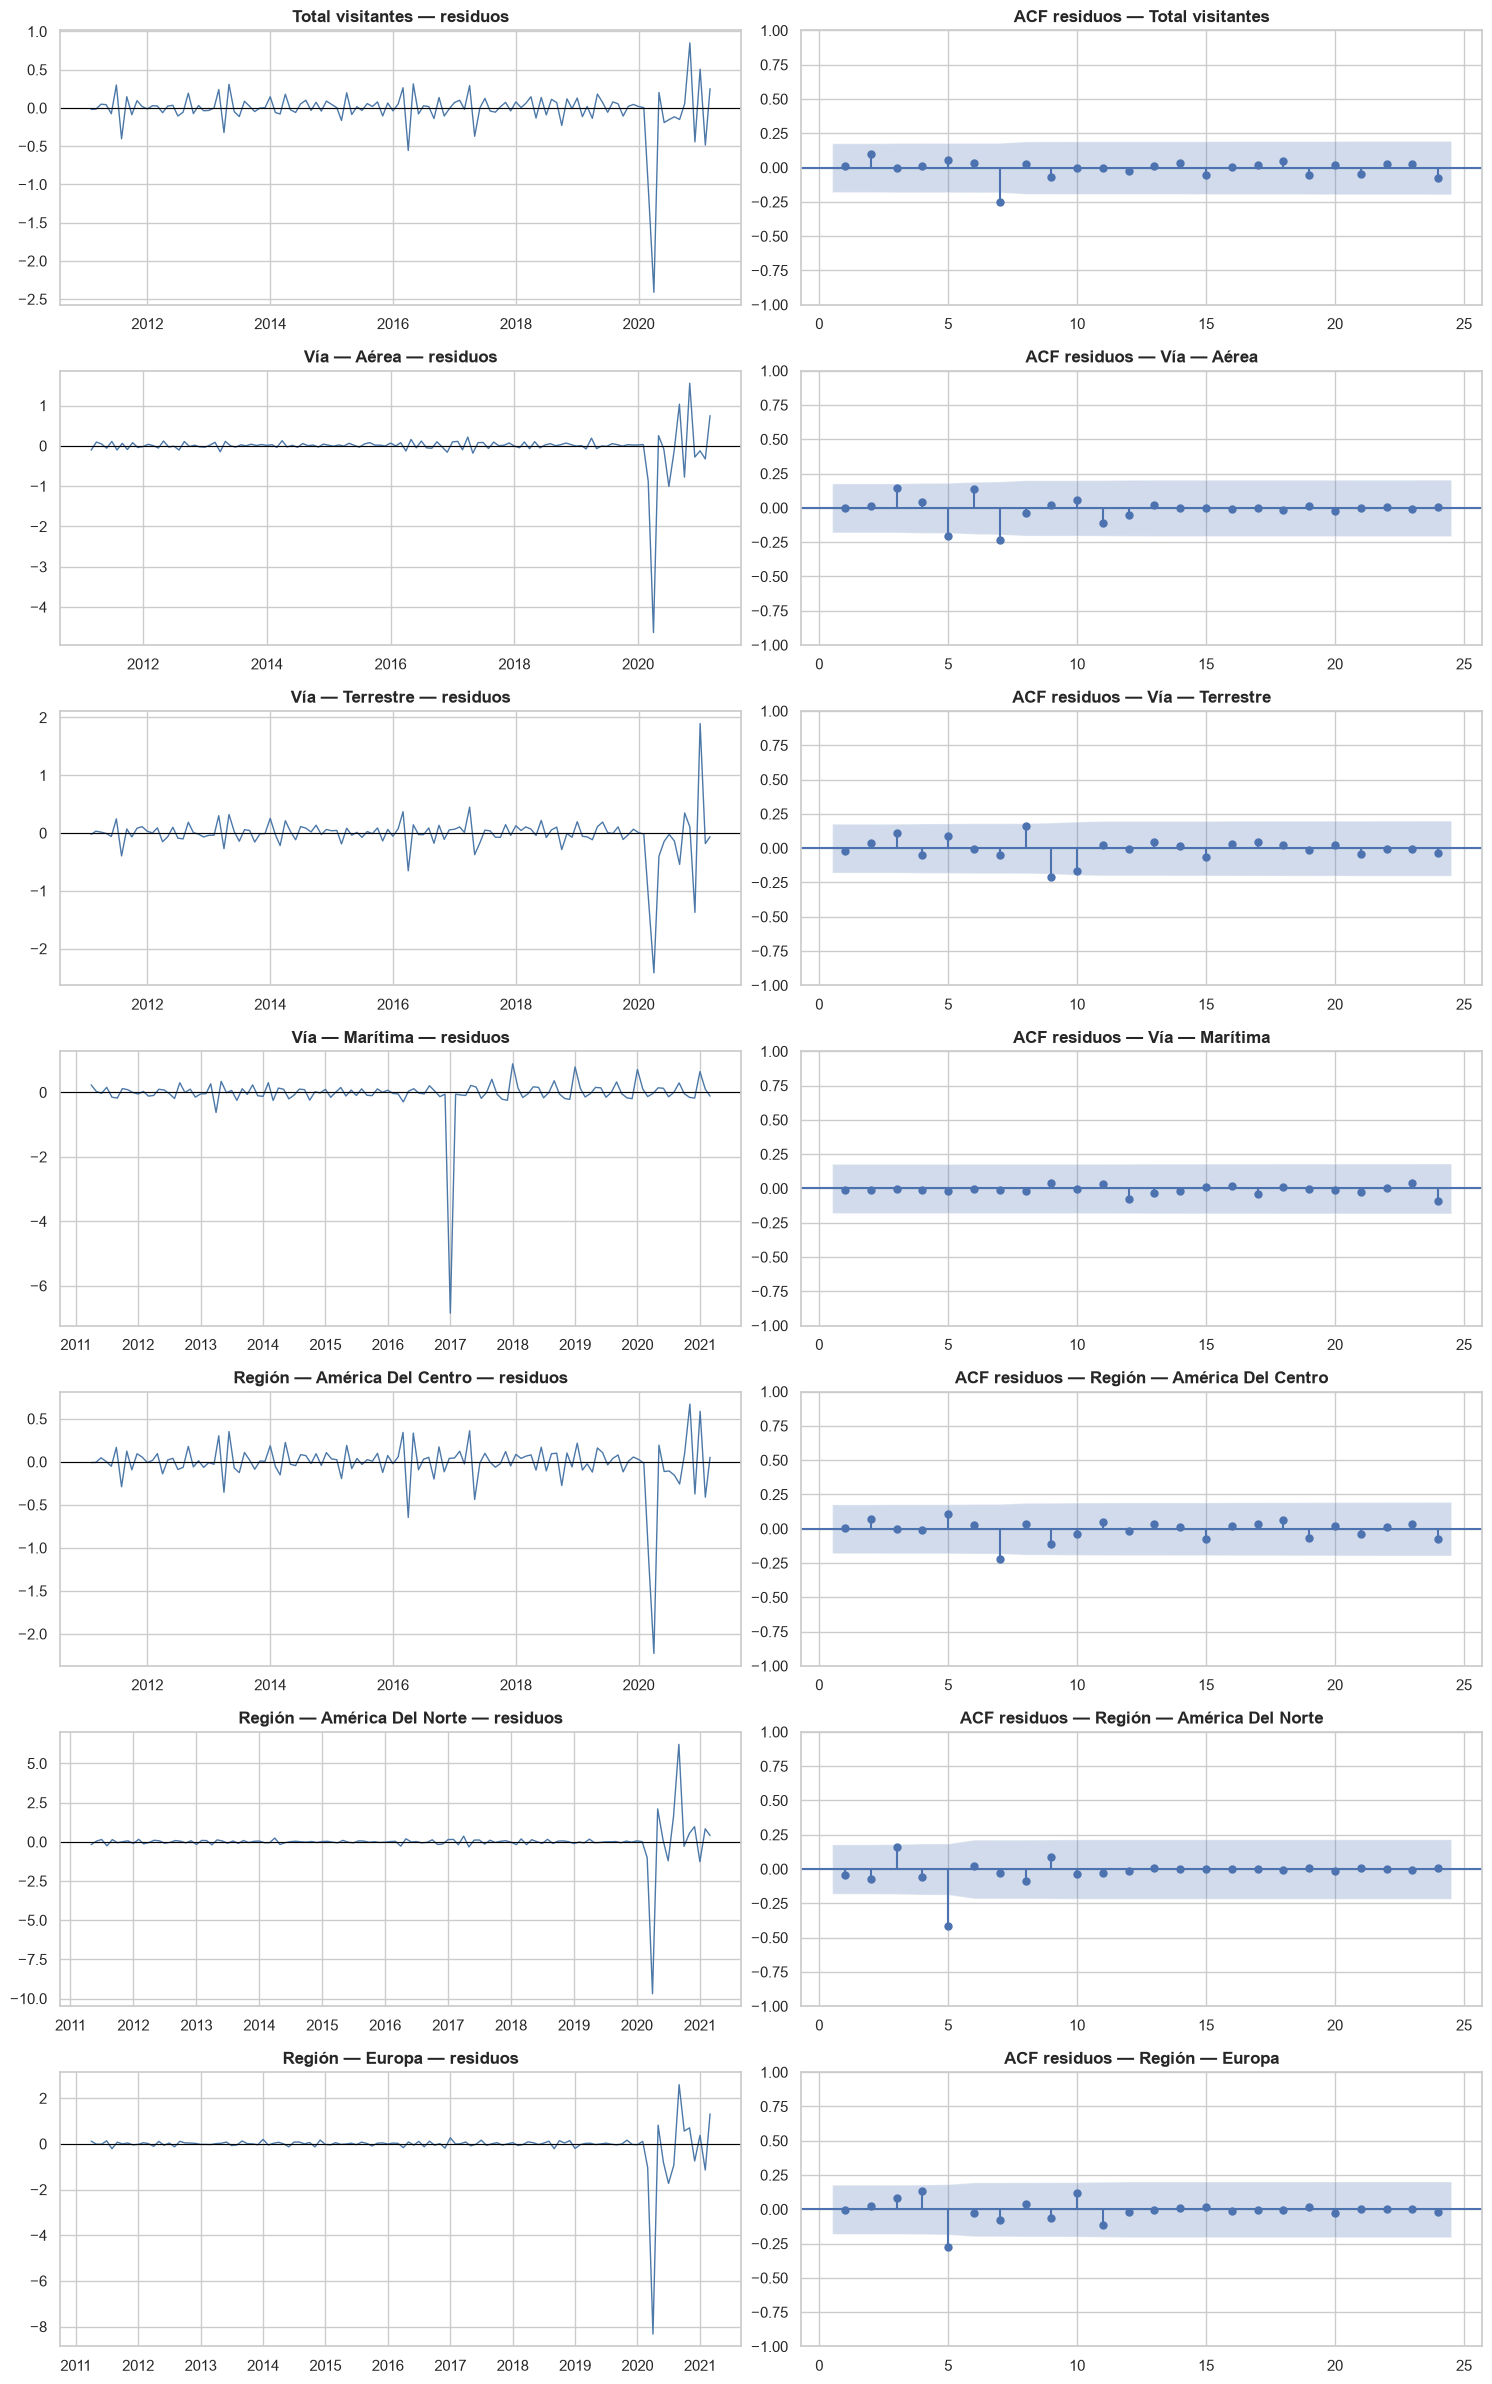

,Modelo,Media residuos,Desv. residuos,Ljung-Box p(12),Compatible con ruido blanco
Serie,,,,,
Total visitantes,"SARIMA(1,0,1)(1,1,0)[12]",-0.0170,0.2961,0.5185,True
Vía — Aérea,"SARIMA(1,0,1)(0,1,1)[12]",-0.0258,0.4887,0.0540,True
Vía — Terrestre,"SARIMA(1,0,1)(1,1,0)[12]",-0.0262,0.3605,0.1720,True
Vía — Marítima,"SARIMA(1,1,1)(0,1,1)[12]",-0.0365,0.6614,0.9999,True
Región — América Del Centro,"SARIMA(1,0,1)(1,1,0)[12]",-0.0167,0.2845,0.5386,True
Región — América Del Norte,"SARIMA(1,1,2)(0,1,1)[12]",-0.0056,1.1169,0.0043,False
Región — Europa,"SARIMA(1,0,2)(0,1,1)[12]",-0.0618,0.8559,0.1144,True


In [12]:
fig, axes = plt.subplots(len(series_df.columns), 2, figsize=(15, 24))
diagnostico_residuos = []

for fila, nombre in enumerate(series_df.columns):
    ajuste = mejores_arima[nombre]['ajuste']
    burn = max(12, int(getattr(ajuste, 'loglikelihood_burn', 0)))
    residuos = ajuste.resid.iloc[burn:].dropna()
    p_ljung = float(acorr_ljungbox(residuos, lags=[12], return_df=True)['lb_pvalue'].iloc[0])
    diagnostico_residuos.append({
        'Serie': nombre,
        'Modelo': mejores_arima[nombre]['etiqueta'],
        'Media residuos': residuos.mean(),
        'Desv. residuos': residuos.std(),
        'Ljung-Box p(12)': p_ljung,
        'Compatible con ruido blanco': p_ljung > 0.05
    })
    axes[fila,0].plot(residuos.index, residuos, color='#4C78A8', linewidth=1)
    axes[fila,0].axhline(0, color='black', linewidth=.8)
    axes[fila,0].set_title(f'{nombre} — residuos')
    plot_acf(residuos, lags=24, zero=False, ax=axes[fila,1])
    axes[fila,1].set_title(f'ACF residuos — {nombre}')

plt.tight_layout(); plt.show()
diagnostico_residuos = pd.DataFrame(diagnostico_residuos).set_index('Serie')
display(diagnostico_residuos.style.format({
    'Media residuos':'{:.4f}', 'Desv. residuos':'{:.4f}', 'Ljung-Box p(12)':'{:.4f}'
}))

### Conclusión del diagnóstico de residuos

Después de retirar el período de inicialización, seis de los siete modelos presentan valores Ljung–Box mayores que 0.05 y residuos aproximadamente centrados en cero. Esto indica que capturan razonablemente la dependencia temporal. La excepción es América del Norte (`p=0.0043`), donde permanece autocorrelación; su SARIMA puede mejorarse y debe contrastarse especialmente con los métodos alternativos.

## 5.4 Modelos alternativos

- **Seasonal naïve:** repite el valor observado en el mismo mes del último año de entrenamiento.
- **Suavizamiento exponencial simple:** actualiza el nivel dando mayor peso a los datos recientes; no modela explícitamente tendencia ni estacionalidad.
- **Holt–Winters:** combina nivel, tendencia amortiguada y estacionalidad aditiva de 12 meses.
- **Prophet:** estima una tendencia por tramos y una estacionalidad anual flexible.

Los pronósticos negativos se recortan a cero porque el volumen de visitantes no puede ser negativo.

In [13]:
modelos_alternativos = {}

for nombre in series_df.columns:
    y_train = train[nombre].astype(float)
    horizonte = len(test)
    modelos_alternativos[nombre] = {}

    predicciones[nombre]['Seasonal naïve'] = pd.Series(
        seasonal_naive(y_train, horizonte), index=test.index
    )

    ajuste_ses = SimpleExpSmoothing(
        y_train, initialization_method='estimated'
    ).fit(optimized=True)
    predicciones[nombre]['Suavizamiento exponencial'] = pd.Series(
        np.maximum(np.asarray(ajuste_ses.forecast(horizonte)), 0), index=test.index
    )
    modelos_alternativos[nombre]['Suavizamiento exponencial'] = ajuste_ses

    ajuste_hw = ExponentialSmoothing(
        y_train, trend='add', damped_trend=True,
        seasonal='add', seasonal_periods=12,
        initialization_method='estimated'
    ).fit(optimized=True, use_brute=True)
    predicciones[nombre]['Holt-Winters'] = pd.Series(
        np.maximum(np.asarray(ajuste_hw.forecast(horizonte)), 0), index=test.index
    )
    modelos_alternativos[nombre]['Holt-Winters'] = ajuste_hw

    datos_prophet = pd.DataFrame({'ds': y_train.index, 'y': y_train.values})
    modelo_prophet = Prophet(
        yearly_seasonality=True, weekly_seasonality=False,
        daily_seasonality=False, seasonality_mode='additive',
        changepoint_prior_scale=0.10, uncertainty_samples=0
    )
    modelo_prophet.fit(datos_prophet)
    futuro = pd.DataFrame({'ds': test.index})
    pred_prophet = modelo_prophet.predict(futuro)['yhat'].to_numpy()
    predicciones[nombre]['Prophet'] = pd.Series(
        np.maximum(pred_prophet, 0), index=test.index
    )
    modelos_alternativos[nombre]['Prophet'] = modelo_prophet

print('Modelos alternativos ajustados para las siete series.')

Modelos alternativos ajustados para las siete series.


## 5.5 Evaluación sobre el conjunto de prueba

MAE expresa el error absoluto típico en personas y RMSE penaliza con mayor intensidad los errores grandes. El modelo con menor RMSE se selecciona como ganador de cada serie; MAE se usa para confirmar que la decisión no dependa únicamente de unos pocos errores extremos.

In [14]:
filas_metricas = []
for nombre in series_df.columns:
    for modelo, pronostico in predicciones[nombre].items():
        valores = calcular_metricas(test[nombre], pronostico)
        filas_metricas.append({'Serie': nombre, 'Modelo': modelo, **valores})

metricas_modelos = pd.DataFrame(filas_metricas)
metricas_modelos['Ranking RMSE'] = metricas_modelos.groupby('Serie')['RMSE'].rank(method='min')
metricas_modelos['Ranking MAE'] = metricas_modelos.groupby('Serie')['MAE'].rank(method='min')
metricas_modelos = metricas_modelos.sort_values(['Serie','RMSE'])

display(metricas_modelos.style.format({
    'MAE':'{:,.0f}', 'RMSE':'{:,.0f}', 'Ranking RMSE':'{:.0f}', 'Ranking MAE':'{:.0f}'
}).background_gradient(subset=['RMSE'], cmap='RdYlGn_r'))

mejor_por_serie = (metricas_modelos.sort_values('RMSE')
                    .groupby('Serie', as_index=False).first()
                    .set_index('Serie'))
display(mejor_por_serie[['Modelo','MAE','RMSE']].style.format({'MAE':'{:,.0f}','RMSE':'{:,.0f}'}))

,Serie,Modelo,MAE,RMSE,Ranking RMSE,Ranking MAE
23,Región — América Del Centro,Holt-Winters,"108,192","117,775",1,1
22,Región — América Del Centro,Suavizamiento exponencial,"109,867","121,961",2,2
20,Región — América Del Centro,ARIMA/SARIMA,"125,534","140,146",3,3
21,Región — América Del Centro,Seasonal naïve,"134,400","144,899",4,4
24,Región — América Del Centro,Prophet,"151,589","164,833",5,5
28,Región — América Del Norte,Holt-Winters,"40,351","43,885",1,2
27,Región — América Del Norte,Suavizamiento exponencial,"39,603","44,299",2,1
26,Región — América Del Norte,Seasonal naïve,"49,974","53,533",3,3
25,Región — América Del Norte,ARIMA/SARIMA,"52,534","56,615",4,5
29,Región — América Del Norte,Prophet,"51,971","57,182",5,4


,Modelo,MAE,RMSE
Serie,,,
Región — América Del Centro,Holt-Winters,"108,192","117,775"
Región — América Del Norte,Holt-Winters,"40,351","43,885"
Región — Europa,ARIMA/SARIMA,"9,998","10,946"
Total visitantes,Suavizamiento exponencial,"165,373","180,598"
Vía — Aérea,Suavizamiento exponencial,"36,971","42,141"
Vía — Marítima,Seasonal naïve,0,0
Vía — Terrestre,Suavizamiento exponencial,"121,715","134,136"


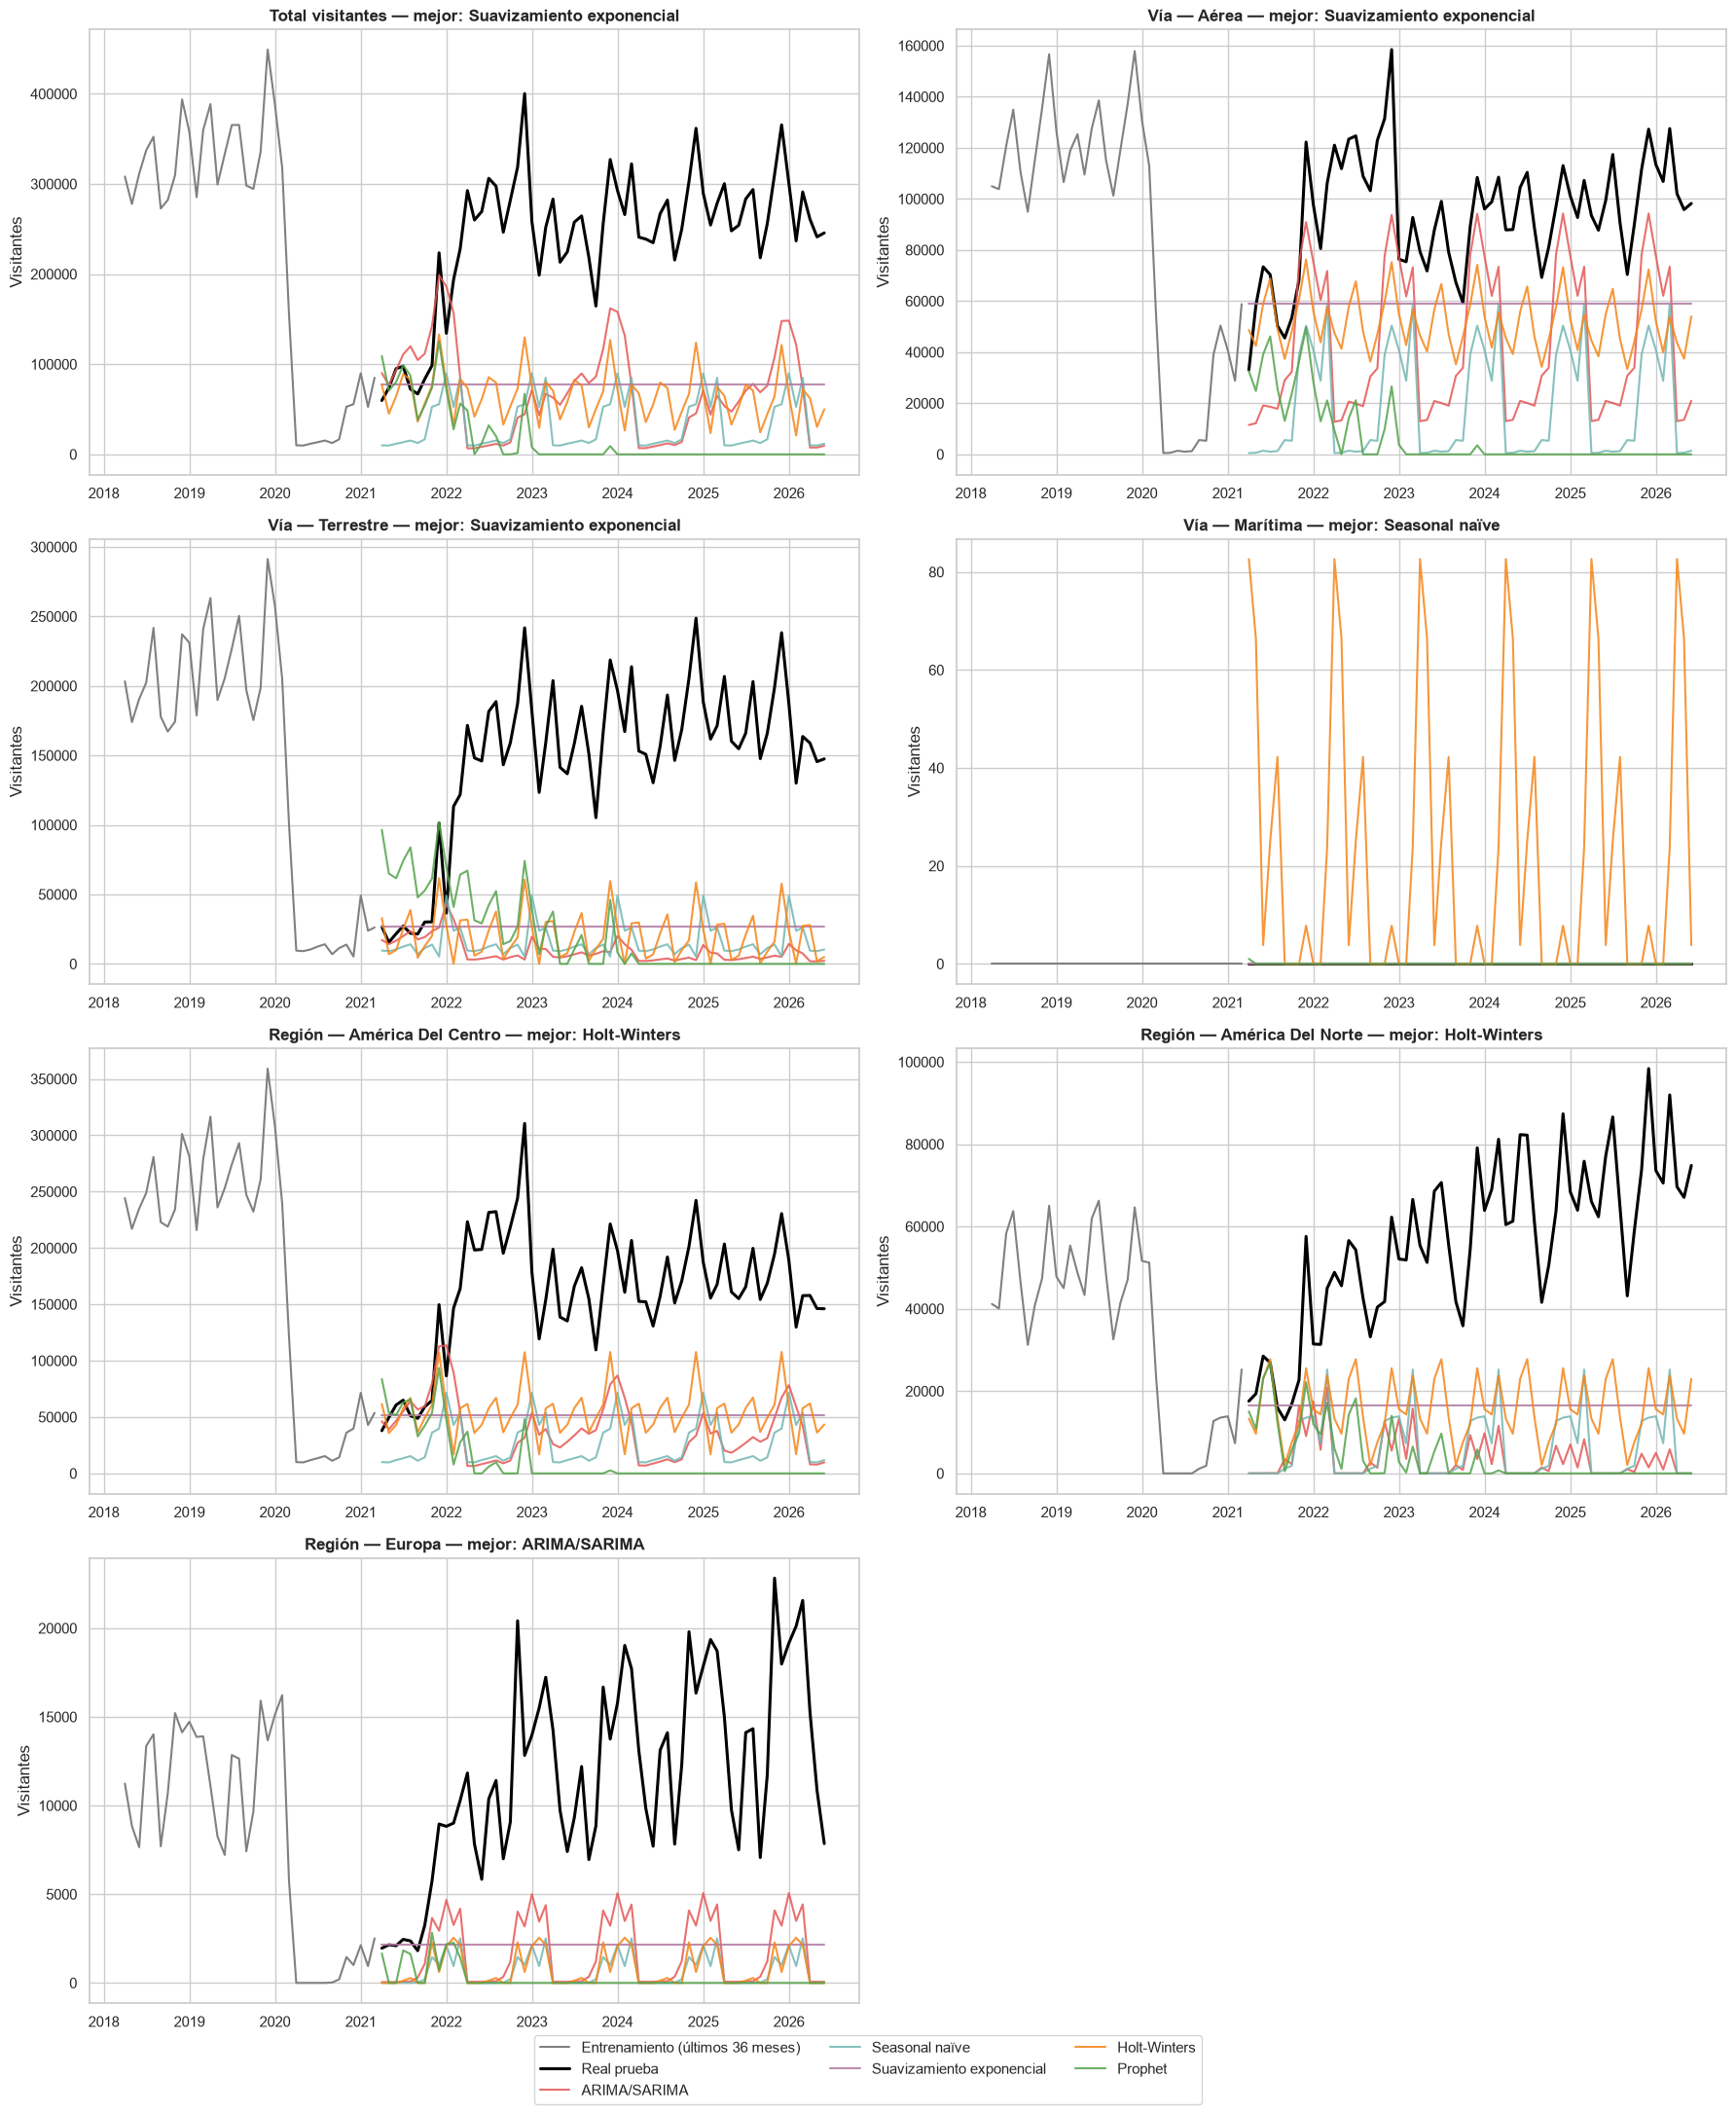

In [15]:
colores = {
    'ARIMA/SARIMA':'#E45756', 'Seasonal naïve':'#72B7B2',
    'Suavizamiento exponencial':'#B279A2', 'Holt-Winters':'#F58518',
    'Prophet':'#54A24B'
}

fig, axes = plt.subplots(4, 2, figsize=(18, 22), sharex=False)
axes = axes.flat
for ax, nombre in zip(axes, series_df.columns):
    ax.plot(train[nombre].iloc[-36:], color='gray', label='Entrenamiento (últimos 36 meses)')
    ax.plot(test[nombre], color='black', linewidth=2.2, label='Real prueba')
    for modelo, pronostico in predicciones[nombre].items():
        ax.plot(pronostico, color=colores[modelo], alpha=.85, label=modelo)
    ganador = mejor_por_serie.loc[nombre, 'Modelo']
    ax.set_title(f'{nombre} — mejor: {ganador}')
    ax.set_ylabel('Visitantes')
axes[-1].axis('off')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(.5, .01))
plt.tight_layout(rect=(0,.04,1,1)); plt.show()

### Conclusión de la evaluación predictiva

La comparación se realiza sobre un horizonte particularmente difícil: el entrenamiento termina en marzo de 2021, cerca del punto más bajo causado por la pandemia, mientras que la prueba contiene la reapertura y recuperación hasta junio de 2026. Por ello, los errores reflejan tanto la calidad del modelo como un cambio estructural que no podía conocerse usando únicamente el conjunto de entrenamiento.

El suavizamiento exponencial obtiene el menor RMSE para el total, la vía aérea y la terrestre. Holt–Winters resulta mejor para América del Centro y América del Norte, mientras que ARIMA/SARIMA gana por un margen pequeño en Europa. En la vía marítima, seasonal naïve obtiene error cero porque la serie comparable registra ceros durante todo el conjunto de prueba; esto refleja la cobertura y metodología de la fuente, no evidencia de ausencia real de actividad marítima.

# 6. Análisis comparativo final

In [16]:
comparacion_categorias = []
for categoria, prefijo in [('Vías de ingreso','Vía — '), ('Regiones geográficas','Región — ')]:
    tabla = comparativo.loc[comparativo.index.str.startswith(prefijo)]
    comparacion_categorias.append({
        'Categoría': categoria,
        'Mayor estacionalidad': tabla['Fuerza estacional'].idxmax(),
        'Mayor crecimiento': tabla['Tendencia pre-COVID (personas/mes)'].idxmax(),
        'Mayor volatilidad': tabla['Volatilidad pre-COVID'].idxmax(),
        'Más afectada por pandemia': tabla['Impacto 2020 vs 2019'].dropna().idxmin()
    })
comparacion_categorias = pd.DataFrame(comparacion_categorias).set_index('Categoría')
display(comparacion_categorias)

resumen_modelos = mejor_por_serie[['Modelo','MAE','RMSE']].copy()
display(resumen_modelos.style.format({'MAE':'{:,.0f}','RMSE':'{:,.0f}'}))

,Mayor estacionalidad,Mayor crecimiento,Mayor volatilidad,Más afectada por pandemia
Categoría,,,,
Vías de ingreso,Vía — Aérea,Vía — Terrestre,Vía — Terrestre,Vía — Terrestre
Regiones geográficas,Región — Europa,Región — América Del Centro,Región — Europa,Región — América Del Centro


,Modelo,MAE,RMSE
Serie,,,
Región — América Del Centro,Holt-Winters,"108,192","117,775"
Región — América Del Norte,Holt-Winters,"40,351","43,885"
Región — Europa,ARIMA/SARIMA,"9,998","10,946"
Total visitantes,Suavizamiento exponencial,"165,373","180,598"
Vía — Aérea,Suavizamiento exponencial,"36,971","42,141"
Vía — Marítima,Seasonal naïve,0,0
Vía — Terrestre,Suavizamiento exponencial,"121,715","134,136"


## 6.1 Conclusiones y utilidad para INGUAT

### Comparación entre vías y regiones

- Entre las vías, la aérea presenta el patrón estacional más fuerte; la terrestre aporta el mayor crecimiento absoluto previo a 2020, la mayor volatilidad relativa y la mayor caída pandémica entre las vías comparables.
- Entre las regiones, Europa muestra la mayor estacionalidad y volatilidad; América del Centro tiene el mayor crecimiento absoluto y fue la más afectada por la pandemia.
- La serie marítima de visitantes comparables tiene niveles pequeños e irregularidades metodológicas; sus resultados deben interpretarse con especial cautela.

### Hallazgos útiles para la toma de decisiones

1. La fuerte concentración terrestre y centroamericana justifica coordinar capacidad, información turística y atención en los principales pasos fronterizos.
2. La estacionalidad permite anticipar meses de mayor demanda y distribuir campañas, personal e infraestructura antes de los picos.
3. Los mercados aéreos y europeos presentan patrones distintos de los flujos regionales terrestres, por lo que no conviene aplicar una única estrategia de promoción.
4. La pandemia y el cambio metodológico de 2023 demuestran que los pronósticos deben acompañarse de escenarios y monitoreo frecuente; una ruptura externa puede dominar el error de cualquier modelo histórico.
5. Para decisiones operativas conviene actualizar los modelos cada mes y comparar continuamente contra seasonal naïve, que funciona como línea base transparente.

## 6.2 Limitaciones

- El conjunto de prueba incluye una recuperación extraordinaria no observable al momento del entrenamiento.
- Existen cambios de fuente y granularidad desde 2023, especialmente en `Viajero`, cruceros, país y vía marítima.
- Los resultados corresponden a datos académicos y no deben presentarse como cifras oficiales del INGUAT o del Instituto Guatemalteco de Migración.

## 6.3 Resultado final

El laboratorio deja un flujo reproducible desde la auditoría y construcción de las series hasta la selección y evaluación de modelos. Los ganadores son: suavizamiento exponencial para el total y las vías aérea y terrestre; Holt–Winters para América del Centro y América del Norte; ARIMA/SARIMA para Europa; y seasonal naïve para la vía marítima bajo la cobertura disponible. La selección usa RMSE fuera de muestra sin ignorar el diagnóstico de residuos ni la diferencia entre ajuste interno —AIC/BIC— y capacidad predictiva —MAE/RMSE—.